In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path 
import sys,importlib
import re,ast
import joblib
import json , shutil
import xgboost as xgb
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import ndcg_score

In [7]:
ROOT = Path("/workspace")
excel = ROOT / "data/raw/02_CortexHR_AI_ML_Dataset.xlsx"
xls = pd.ExcelFile(excel)
print("WORKBOOK SHEETS:")
for sheet in xls.sheet_names:
    print("-", sheet)
print("\nMODEL FILES:")
for file in sorted((ROOT / "models").glob("*")):
    print(file.name)
scoring_df = pd.read_excel(excel,sheet_name="attrition_scoring_2026")
print("\nSCORING DATASET")
print("Shape:", scoring_df.shape)
print("\nColumns:")
print(scoring_df.columns.tolist())

WORKBOOK SHEETS:
- README
- data_dictionary
- attrition_dataset
- protected_attributes
- attrition_scoring_2026
- engagement_survey
- performance_reviews
- attendance_monthly_features
- attendance_anomaly_labels
- attendance_daily_examples
- payroll_monthly_features
- payroll_anomaly_labels
- monthly_headcount_history
- workforce_events
- salary_training
- job_descriptions
- resumes
- resume_job_labels
- resume_bias_pairs
- resume_protected_attrs
- chatbot_nlu_training
- chatbot_test_set
- chatbot_responses
- hr_faq
- chatbot_dialogues
- baseline_benchmarks
- anomaly_baselines
- sample_attrition_risk
- sample_anomaly_results
- sample_forecast
- answer_key_planted_dirt
- answer_key_notes

MODEL FILES:
.ipynb_checkpoints
attendance_detector.joblib
attrition-v2.joblib
attrition-v2_metadata.json
attrition_preprocessor.joblib
chatbot_bundle.joblib
metadata.json
payroll_detector.joblib
reason_codes.joblib
resume_ranking_bundle.joblib

SCORING DATASET
Shape: (430, 34)

Columns:
['row_id', 'em

In [8]:
ROOT = Path("/workspace")
model_path = ROOT / "models/attrition-v2.joblib"
metadata_path = ROOT / "models/attrition-v2_metadata.json"
attrition_v2 = joblib.load(model_path)
print("MODEL TYPE:")
print(type(attrition_v2))
with open(metadata_path, "r") as f:
    metadata = json.load(f)
print("\nMODEL METADATA:")
print(json.dumps(metadata, indent=2, default=str))

MODEL TYPE:
<class 'sklearn.calibration.CalibratedClassifierCV'>

MODEL METADATA:
{
  "model_version": "attrition-v2",
  "model_type": "XGBoost with sigmoid calibration",
  "target": "left_within_12m",
  "training_rows": 2389,
  "feature_count": 61,
  "positive_cases": 349,
  "negative_cases": 2040,
  "positive_rate": 0.1460862285475094,
  "numeric_features": [
    "job_level",
    "tenure_months",
    "total_experience_years",
    "previous_employers_count",
    "commute_distance_km",
    "annual_fixed_pay",
    "comp_ratio",
    "raises_received",
    "last_raise_pct",
    "months_since_last_raise",
    "promotions_received",
    "months_since_last_promotion",
    "internal_transfers",
    "last_performance_rating",
    "last_engagement_score",
    "manager_changes_12m",
    "training_hours_12m",
    "attendance_rate_3m",
    "late_arrivals_3m",
    "avg_overtime_hours_per_month_3m",
    "avg_hours_worked_3m",
    "wfh_share_3m",
    "unpaid_leave_days_6m",
    "paid_leave_days_6m",


In [11]:
scoring_df = pd.read_excel(ROOT / "data/raw/02_CortexHR_AI_ML_Dataset.xlsx",sheet_name="attrition_scoring_2026")
expected_features = (metadata["numeric_features"]+ metadata["categorical_features"])
available_features = [
    col for col in expected_features
    if col in scoring_df.columns
]
missing_features = [
    col for col in expected_features
    if col not in scoring_df.columns
]
unexpected_columns = [
    col for col in scoring_df.columns
    if col not in expected_features
]
print("MODEL FEATURE COUNT:", len(expected_features))
print("AVAILABLE MODEL FEATURES:", len(available_features))
print("MISSING MODEL FEATURES:", len(missing_features))
print("\nAVAILABLE FEATURES:")
print(available_features)
print("\nMISSING FEATURES:")
for i, feature in enumerate(missing_features, 1):
    print(f"{i:02d}. {feature}")
print(unexpected_columns)

MODEL FEATURE COUNT: 61
AVAILABLE MODEL FEATURES: 31
MISSING MODEL FEATURES: 30

AVAILABLE FEATURES:
['job_level', 'tenure_months', 'total_experience_years', 'previous_employers_count', 'commute_distance_km', 'annual_fixed_pay', 'comp_ratio', 'raises_received', 'last_raise_pct', 'months_since_last_raise', 'promotions_received', 'months_since_last_promotion', 'internal_transfers', 'last_performance_rating', 'last_engagement_score', 'manager_changes_12m', 'training_hours_12m', 'attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'avg_hours_worked_3m', 'wfh_share_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m', 'dept_attrition_rate_prior_12m', 'department_id', 'role_id', 'work_location', 'work_mode', 'employment_type', 'highest_education']

MISSING FEATURES:
01. attendance_scheduled_days
02. attendance_present_days
03. attendance_wfh_days
04. attendance_half_days_unpaid
05. attendance_paid_leave_days
06. attendance_unpaid_absence_days
07. attendance_longest_unpai

In [12]:
# Load source sheets

In [16]:
attendance_df = pd.read_excel(excel,sheet_name="attendance_monthly_features")
payroll_df = pd.read_excel(excel,sheet_name="payroll_monthly_features")

In [14]:
print("Shape:", attendance_df.shape)
print("Columns:")
print(attendance_df.columns.tolist())
print("\nSample records:")
display(attendance_df.head(3))

Shape: (7339, 16)
Columns:
['attendance_feature_id', 'employee_id', 'month', 'department_id', 'job_level', 'scheduled_days', 'present_days', 'wfh_days', 'half_days_unpaid', 'paid_leave_days', 'unpaid_absence_days', 'longest_unpaid_streak_days', 'late_arrivals', 'avg_hours_worked', 'overtime_hours', 'attendance_rate']

Sample records:


,attendance_feature_id,employee_id,month,department_id,job_level,scheduled_days,present_days,wfh_days,half_days_unpaid,paid_leave_days,unpaid_absence_days,longest_unpaid_streak_days,late_arrivals,avg_hours_worked,overtime_hours,attendance_rate
0,AF-00001,EMP-0002,2025-04-01,D08,4,20,20,18,0,0,0,0,1,8.50,0.0,1.0000
1,AF-00002,EMP-0002,2025-05-01,D08,4,21,20,18,1,0,0,0,2,8.71,0.0,0.9762
2,AF-00003,EMP-0002,2025-06-01,D08,4,21,19,18,1,1,0,0,1,8.25,0.0,0.9286


In [17]:
print("Shape:", payroll_df.shape)
print("Columns:")
print(payroll_df.columns.tolist())
print("\nSample records:")
display(payroll_df.head(3))
print(scoring_df["observation_date"].describe())

Shape: (7355, 23)
Columns:
['payroll_item_id', 'run_id', 'employee_id', 'month', 'department_id', 'role_id', 'job_level', 'overtime_eligible', 'monthly_fixed_gross', 'payable_days', 'lop_days', 'overtime_hours_paid', 'overtime_pay', 'variable_pay', 'variable_pay_type', 'gross_pay', 'pf_employee', 'esi_employee', 'professional_tax', 'tds', 'other_deductions', 'total_deductions', 'net_pay']

Sample records:


,payroll_item_id,run_id,employee_id,month,department_id,role_id,job_level,overtime_eligible,monthly_fixed_gross,payable_days,...,variable_pay,variable_pay_type,gross_pay,pf_employee,esi_employee,professional_tax,tds,other_deductions,total_deductions,net_pay
0,PI-000001,PR-2025-04,EMP-0002,2025-04-01,D08,R047,4,N,144460.0,30.0,...,34670.40,Performance Bonus,179130.40,1800.0,0.0,200,18625.79,0,20625.79,158504.61
1,PI-000002,PR-2025-04,EMP-0004,2025-04-01,D03,R017,3,N,103938.0,30.0,...,56126.52,Performance Bonus,160064.52,1800.0,0.0,200,29517.82,0,31517.82,128546.70
2,PI-000003,PR-2025-04,EMP-0006,2025-04-01,D00,R001,7,N,479009.0,30.0,...,0.00,NaN,479009.00,1800.0,0.0,200,111100.81,0,113100.81,365908.19


count                    430
mean     2026-09-30 00:00:00
min      2026-09-30 00:00:00
25%      2026-09-30 00:00:00
50%      2026-09-30 00:00:00
75%      2026-09-30 00:00:00
max      2026-09-30 00:00:00
Name: observation_date, dtype: object


In [ ]:
# Convert dates

In [ ]:
# Our task 14 scoring dataset contains 430 employees but the V2 attrition model requires historical attendance and payroll information to generate account risk prediction
# What are we checking?
# 1. Historical date coverage
# 2. Employee coverage
# 3. Scoring employee matching
# 4. Duplicate employee-month records
# 5. Monthly coverage

In [24]:
attendance_df["month"] = pd.to_datetime(attendance_df["month"])
payroll_df["month"] = pd.to_datetime(payroll_df["month"])
scoring_ids = set(scoring_df["employee_id"])

In [22]:
print("Date range:", attendance_df["month"].min(), "to", attendance_df["month"].max())
print("Unique employees:", attendance_df["employee_id"].nunique())
print("Scoring employees found:", attendance_df["employee_id"].isin(scoring_ids).sum())
print("Unique scoring employees found:",
      attendance_df.loc[attendance_df["employee_id"].isin(scoring_ids),"employee_id"].nunique())
print("Duplicate employee-month records:",
      attendance_df.duplicated(["employee_id", "month"]).sum())

Date range: 2025-04-01 00:00:00 to 2026-09-01 00:00:00
Unique employees: 528
Scoring employees found: 6454
Unique scoring employees found: 430
Duplicate employee-month records: 0


In [23]:
print("\nMonthly coverage:")
display(attendance_df.groupby("month")["employee_id"].nunique().to_frame("employees"))


Monthly coverage:


,employees
month,
2025-04-01,386
2025-05-01,386
2025-06-01,392
2025-07-01,394
2025-08-01,399
2025-09-01,397
2025-10-01,403
2025-11-01,399
2025-12-01,403


In [20]:
print("PAYROLL HISTORY")
print("Date range:", payroll_df["month"].min(), "to", payroll_df["month"].max())
print("Unique employees:", payroll_df["employee_id"].nunique())
print("Scoring employees found:", payroll_df["employee_id"].isin(scoring_ids).sum())
print("Unique scoring employees found:",payroll_df.loc[payroll_df["employee_id"].isin(scoring_ids),"employee_id"].nunique())
print("Duplicate employee-month records:",payroll_df.duplicated(["employee_id", "month"]).sum())

PAYROLL HISTORY
Date range: 2025-04-01 00:00:00 to 2026-09-01 00:00:00
Unique employees: 528
Scoring employees found: 6466
Unique scoring employees found: 430
Duplicate employee-month records: 15


In [21]:
print("\nMonthly coverage:")
display(payroll_df.groupby("month")["employee_id"].nunique().to_frame("employees"))


Monthly coverage:


,employees
month,
2025-04-01,386
2025-05-01,386
2025-06-01,392
2025-07-01,394
2025-08-01,399
2025-09-01,397
2025-10-01,403
2025-11-01,399
2025-12-01,403


In [ ]:
# Find duplicated employee-month records
# In the previous block, we discovered that the payroll dataset contains duplicate employee-month records.
# Are these duplicate records carrying different information or they identical records repeated more than once

In [26]:
duplicate_mask = payroll_df.duplicated(["employee_id", "month"],keep=False)
payroll_duplicates = payroll_df.loc[duplicate_mask].copy()
print("DUPLICATE ROWS:", len(payroll_duplicates))
print("DUPLICATE EMPLOYEE-MONTH GROUPS:",payroll_duplicates.groupby(["employee_id", "month"]).ngroups)

DUPLICATE ROWS: 30
DUPLICATE EMPLOYEE-MONTH GROUPS: 15


In [27]:
comparison_cols = [
    col for col in payroll_df.columns
    if col not in ["payroll_item_id"]
]
duplicate_check = (payroll_duplicates.groupby(["employee_id", "month"])[comparison_cols].nunique(dropna=False))
print("\nMAXIMUM DISTINCT VALUES WITHIN EACH DUPLICATE GROUP:")
display(duplicate_check.max().to_frame("max_distinct_values"))
all_identical = duplicate_check.le(1).all().all()
print("\nAll duplicate groups identical except payroll_item_id:", all_identical)
print("\nDUPLICATE RECORD SAMPLES:")
display(payroll_duplicates.sort_values(["employee_id", "month"]).head(10))


MAXIMUM DISTINCT VALUES WITHIN EACH DUPLICATE GROUP:


,max_distinct_values
run_id,1
employee_id,1
month,1
department_id,1
role_id,1
job_level,1
overtime_eligible,1
monthly_fixed_gross,1
payable_days,1
lop_days,1



All duplicate groups identical except payroll_item_id: True

DUPLICATE RECORD SAMPLES:


,payroll_item_id,run_id,employee_id,month,department_id,role_id,job_level,overtime_eligible,monthly_fixed_gross,payable_days,...,variable_pay,variable_pay_type,gross_pay,pf_employee,esi_employee,professional_tax,tds,other_deductions,total_deductions,net_pay
3975,PI-003970,PR-2026-02,EMP-0012,2026-02-01,D01,R004,2,N,53915.0,28.0,...,0.0,NaN,53915.0,1800.0,0.0,200,0.00,0,2000.00,51915.00
3976,PI-D00007,PR-2026-02,EMP-0012,2026-02-01,D01,R004,2,N,53915.0,28.0,...,0.0,NaN,53915.0,1800.0,0.0,200,0.00,0,2000.00,51915.00
5673,PI-005661,PR-2026-06,EMP-0092,2026-06-01,D08,R045,2,Y,73903.0,30.0,...,0.0,NaN,73903.0,1800.0,0.0,200,0.00,0,2000.00,71903.00
5674,PI-D00015,PR-2026-06,EMP-0092,2026-06-01,D08,R045,2,Y,73903.0,30.0,...,0.0,NaN,73903.0,1800.0,0.0,200,0.00,0,2000.00,71903.00
2416,PI-002412,PR-2025-10,EMP-0112,2025-10-01,D01,R009,6,N,332694.0,31.0,...,10000.0,Festival Bonus,342694.0,1800.0,0.0,200,68570.53,0,70570.53,272123.47
2417,PI-D00002,PR-2025-10,EMP-0112,2025-10-01,D01,R009,6,N,332694.0,31.0,...,10000.0,Festival Bonus,342694.0,1800.0,0.0,200,68570.53,0,70570.53,272123.47
4058,PI-004052,PR-2026-02,EMP-0179,2026-02-01,D06,R035,3,N,88641.0,28.0,...,0.0,NaN,88641.0,1800.0,0.0,200,0.00,0,2000.00,86641.00
4059,PI-D00001,PR-2026-02,EMP-0179,2026-02-01,D06,R035,3,N,88641.0,28.0,...,0.0,NaN,88641.0,1800.0,0.0,200,0.00,0,2000.00,86641.00
496,PI-000497,PR-2025-05,EMP-0218,2025-05-01,D02,R013,4,N,178808.0,31.0,...,0.0,NaN,178808.0,1800.0,0.0,200,18865.08,0,20865.08,157942.92
497,PI-D00008,PR-2025-05,EMP-0218,2025-05-01,D02,R013,4,N,178808.0,31.0,...,0.0,NaN,178808.0,1800.0,0.0,200,18865.08,0,20865.08,157942.92


In [ ]:
# Keep the original payroll_df unchanged.
# Remove only records identical across all columns except payroll_item_id.

In [28]:
payroll_clean = payroll_df.drop_duplicates(subset=comparison_cols,keep="first").copy()
print("ORIGINAL PAYROLL ROWS:", len(payroll_df))
print("CLEANED PAYROLL ROWS:", len(payroll_clean))
print("REMOVED EXACT DUPLICATES:", len(payroll_df) - len(payroll_clean))
print("REMAINING DUPLICATES:",payroll_clean.duplicated(["employee_id", "month"]).sum())
print("UNIQUE EMPLOYEES:",payroll_clean["employee_id"].nunique())
print("\nPAYROLL CLEANING VALIDATION:")
print("Original data preserved:", len(payroll_df) == 7355)
print("Expected cleaned rows:", len(payroll_clean) == 7340)
print("No duplicate employee-month records:",not payroll_clean.duplicated(["employee_id", "month"]).any())

ORIGINAL PAYROLL ROWS: 7355
CLEANED PAYROLL ROWS: 7340
REMOVED EXACT DUPLICATES: 15
REMAINING DUPLICATES: 0
UNIQUE EMPLOYEES: 528

PAYROLL CLEANING VALIDATION:
Original data preserved: True
Expected cleaned rows: True
No duplicate employee-month records: True


In [29]:
# trying to find the Task 2 feature engineering logic so we could reconstruct the current task instead of writing new logic

In [31]:
notebooks = [
    p for p in ROOT.rglob("*.ipynb")
    if ".ipynb_checkpoints" not in p.parts]
print("NOTEBOOKS FOUND:")
for nb in notebooks:
    print("-", nb.relative_to(ROOT))

NOTEBOOKS FOUND:
- 01_data_audit_exploration.ipynb
- 02_feature_pipeline.ipynb
- 03_baseline.ipynb
- 04_evaluation.ipynb
- 05_attendance_anomaly.ipynb
- 06_payroll_outlier_detector.ipynb
- 07_payroll_flag_explanations.ipynb
- 08_api.ipynb
- 09_chatbot_intent_classifier.ipynb
- 10_chatbot_memory_premission.ipynb
- 11_rank_resume.ipynb
- 12_resume_fairness_audit.ipynb
- 13_beat_baseline_attrV2model.ipynb
- 14_explainable_risk_reports.ipynb
- 15_fair_pay_bands.ipynb
- Untitled.ipynb
- .Trash-0/files/07_payroll_flag_explanation.ipynb
- .Trash-0/files/14_explainable_risk_reports.ipynb
- .Trash-0/files/reconstructing_the_errores.ipynb
- .Trash-0/files/Untitled 1.ipynb
- .Trash-0/files/Untitled.ipynb
- 05_Starter/notebooks/01_data_audit.ipynb
- 05_Starter/notebooks/02_baselines.ipynb
- data/raw/01_data_audit_exploration.ipynb
- data/raw/02_feature_pipeline.ipynb
- reports/task11/Untitled.ipynb


In [32]:
for nb in notebooks:
    try:
        with open(nb, "r", encoding="utf-8") as f:
            notebook_data = json.load(f)

        matches = []

        for i, cell in enumerate(notebook_data.get("cells", [])):
            source = cell.get("source", [])
            source_text = "".join(source) if isinstance(source, list) else source

            found = [
                feature for feature in missing_features
                if feature in source_text
            ]

            if found:
                matches.append((i, found))

        if matches:
            print(f"\nNOTEBOOK: {nb.relative_to(ROOT)}")
            for cell_no, found in matches:
                print(f"  CELL {cell_no}: {', '.join(found)}")

    except Exception as e:
        print(f"Could not inspect {nb.name}: {e}")


NOTEBOOK: 02_feature_pipeline.ipynb
  CELL 78: tenure_years, raise_overdue, attendance_gap, unpaid_per_month, overtime_load
  CELL 84: tenure_years, raise_overdue, attendance_gap, unpaid_per_month, overtime_load
  CELL 85: tenure_years, raise_overdue, attendance_gap, unpaid_per_month, overtime_load
  CELL 87: tenure_years
  CELL 89: attendance_gap
  CELL 90: tenure_years, attendance_gap

NOTEBOOK: 14_explainable_risk_reports.ipynb
  CELL 23: attendance_scheduled_days, payroll_monthly_fixed_gross
  CELL 30: attendance_gap
  CELL 32: attendance_scheduled_days, attendance_avg_hours_worked, payroll_payable_days, payroll_gross_pay, payroll_net_pay
  CELL 36: tenure_years, raise_overdue, attendance_gap, unpaid_per_month, overtime_load
  CELL 52: attendance_scheduled_days, attendance_present_days, attendance_wfh_days, attendance_half_days_unpaid, attendance_paid_leave_days, attendance_unpaid_absence_days, attendance_longest_unpaid_streak_days, attendance_late_arrivals, attendance_avg_hours_w

In [33]:
task2_path = ROOT / "02_feature_pipeline.ipynb"
with open(task2_path, "r", encoding="utf-8") as f:
    task2_notebook = json.load(f)
cells_to_inspect = [78, 84, 85, 87, 89, 90]
for cell_no in cells_to_inspect:
    cell = task2_notebook["cells"][cell_no]
    source = "".join(cell.get("source", []))
    print(f"TASK 2 — CELL {cell_no}")
    print(source)

TASK 2 — CELL 78
# from pathlib import Path
# feature_code = '''import pandas as pd


# def add_attrition_features(df: pd.DataFrame) -> pd.DataFrame:
    # """Create engineered features for the attrition dataset."""
    # df = df.copy()

    # df["tenure_years"] = df["tenure_months"] / 12

    # df["raise_overdue"] = (
        # df["months_since_last_raise"] > 12
    # ).astype("int8")

    # df["attendance_gap"] = 1 - df["attendance_rate_3m"]

    # df["unpaid_per_month"] = df["unpaid_leave_days_6m"] / 6

    # df["overtime_load"] = (
        # df["avg_overtime_hours_per_month_3m"]
    # )

    # return df

# Path("src/feature.py").write_text(feature_code)
# print("Saved feature functions to src/feature.py")
TASK 2 — CELL 84
new_features = [
    "tenure_years",
    "raise_overdue",
    "attendance_gap",
    "unpaid_per_month",
    "overtime_load"
]
df_features[new_features].head()
TASK 2 — CELL 85
new_features = [
    "tenure_years",
    "raise_overdue",
    "attendance_gap",
    "unp

In [34]:
task13_path = ROOT / "13_beat_baseline_attrV2model.ipynb"
with open(task13_path, "r", encoding="utf-8") as f:
    task13 = json.load(f)
keywords = [
    "attendance_monthly_features",
    "payroll_monthly_features",
    "attendance_scheduled_days",
    "payroll_monthly_fixed_gross",
    "groupby",
    "merge("
]
for i, cell in enumerate(task13["cells"]):
    source = "".join(cell.get("source", []))
    if any(keyword in source for keyword in keywords):
        print(f"TASK 13 — CELL {i}")
        print(source)

TASK 13 — CELL 32
# 2. OUTER FOLD PERFORMANCE
fold_results = []
model_predictions = {
    "V1 Raw": v1_oof,
    "V2 Raw": v2_oof,
    "V2 Sigmoid": v2_sigmoid_oof
}
for fold_number, (train_idx, valid_idx) in enumerate(folds, 1):
    y_valid = y.iloc[valid_idx]
    for model_name, probabilities in model_predictions.items():
        p = probabilities[valid_idx]
        predictions = (p >= 0.5).astype(int)
        fold_results.append({
            "fold": fold_number,
            "model": model_name,
            "roc_auc": roc_auc_score(y_valid, p),
            "pr_auc": average_precision_score(y_valid, p),
            "brier": brier_score_loss(y_valid, p),
            "log_loss": log_loss(
                y_valid,
                np.clip(p, 1e-15, 1 - 1e-15)
            ),
            "precision": precision_score(
                y_valid, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_valid, predictions, zero_division=0
            ),
  

In [35]:
for i, cell in enumerate(task13["cells"]):
    source = "".join(cell.get("source", []))
    if cell.get("cell_type") == "code" and source.strip():
        print(f"CELL {i}")
        print(source[:1200])
        if len(source) > 1200:
            print("... [remaining code omitted]")

CELL 0
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path 
import sys,importlib
import re,ast
import joblib,openpyxl,inspect
import json , shutil
import importlib.metadata as metadata
CELL 1
folders = ["src", "notebooks", "models", "reports", "data"]
CELL 2
for notebook_file in ["03_baseline.ipynb","13_beat_baseline_attrV2model.ipynb"]:
    path = Path(notebook_file)
    print(f"\n{'='*65}")
    print("NOTEBOOK:", notebook_file)
    if not path.exists():
        print("NOT FOUND")
        continue
    with open(path, encoding="utf-8") as f:
        nb = json.load(f)
    print("Total cells:", len(nb["cells"]))
    for i, cell in enumerate(nb["cells"]):
        source = "".join(cell.get("source", []))
        if cell["cell_type"] == "code" and source.strip():
            print(f"\n--- CELL {i} ---")
            print(source[:2500])
        elif cell["cell_type"] == "markdown" and source.strip():
            print(f"\n--- 

In [36]:
# Load the exact dataset used to train Attrition V2
# We are inspectiing the original Task 13 V2 training dataset to understand exactly which features the model was trained on and whether the missing attendance and payroll features are present 

In [38]:
training_features_df = pd.read_csv(ROOT / "data/processed/attrition_features.csv")
print("ORIGINAL V2 TRAINING DATA")
print("Shape:", training_features_df.shape)

print("\nALL TRAINING COLUMNS:")
for i, col in enumerate(training_features_df.columns, 1):
    print(f"{i:02d}. {col}")
print("MISSING FEATURES IN TRAINING DATA")

ORIGINAL V2 TRAINING DATA
Shape: (2389, 72)

ALL TRAINING COLUMNS:
01. row_id
02. employee_id
03. observation_date
04. department_id
05. role_id
06. job_level
07. work_location
08. work_mode
09. employment_type
10. highest_education
11. tenure_months
12. total_experience_years
13. previous_employers_count
14. commute_distance_km
15. annual_fixed_pay
16. comp_ratio
17. raises_received
18. last_raise_pct
19. months_since_last_raise
20. promotions_received
21. months_since_last_promotion
22. internal_transfers
23. last_performance_rating
24. last_engagement_score
25. manager_changes_12m
26. training_hours_12m
27. attendance_rate_3m
28. late_arrivals_3m
29. avg_overtime_hours_per_month_3m
30. avg_hours_worked_3m
31. wfh_share_3m
32. unpaid_leave_days_6m
33. paid_leave_days_6m
34. dept_attrition_rate_prior_12m
35. left_within_12m
36. voluntary_left_within_12m
37. source
38. exit_date
39. resignation_date
40. exit_reason
41. exit_interview_done
42. fnf_settlement_amount
43. attendance_schedu

In [39]:
training_missing = [
    col for col in expected_features
    if col not in training_features_df.columns
]

print("Expected model features:", len(expected_features))
print("Available in training CSV:",
      len([c for c in expected_features if c in training_features_df.columns]))
print("Missing from training CSV:", training_missing)

print("\n" + "=" * 70)
print("CHECK THE 25 ATTENDANCE/PAYROLL FEATURES")
print("=" * 70)

attendance_payroll_features = [
    col for col in missing_features
    if col.startswith(("attendance_", "payroll_"))
]

for col in attendance_payroll_features:
    if col in training_features_df.columns:
        print(f"{col}: PRESENT | dtype={training_features_df[col].dtype}")
    else:
        print(f"{col}: NOT FOUND")

print("\nTRAINING DATA SAMPLE:")
display(training_features_df[expected_features].head(5))

Expected model features: 61
Available in training CSV: 61
Missing from training CSV: []

CHECK THE 25 ATTENDANCE/PAYROLL FEATURES
attendance_scheduled_days: PRESENT | dtype=float64
attendance_present_days: PRESENT | dtype=float64
attendance_wfh_days: PRESENT | dtype=float64
attendance_half_days_unpaid: PRESENT | dtype=float64
attendance_paid_leave_days: PRESENT | dtype=float64
attendance_unpaid_absence_days: PRESENT | dtype=float64
attendance_longest_unpaid_streak_days: PRESENT | dtype=float64
attendance_late_arrivals: PRESENT | dtype=float64
attendance_avg_hours_worked: PRESENT | dtype=float64
attendance_overtime_hours: PRESENT | dtype=float64
attendance_attendance_rate: PRESENT | dtype=float64
payroll_monthly_fixed_gross: PRESENT | dtype=float64
payroll_payable_days: PRESENT | dtype=float64
payroll_lop_days: PRESENT | dtype=float64
payroll_overtime_hours_paid: PRESENT | dtype=float64
payroll_overtime_pay: PRESENT | dtype=float64
payroll_variable_pay: PRESENT | dtype=float64
payroll_g

,job_level,tenure_months,total_experience_years,previous_employers_count,commute_distance_km,annual_fixed_pay,comp_ratio,raises_received,last_raise_pct,months_since_last_raise,...,raise_overdue,attendance_gap,unpaid_per_month,overtime_load,department_id,role_id,work_location,work_mode,employment_type,highest_education
0,4,164.0,30.8,1,12.2,1733520,0.989,6,6.3,5,...,0,0.0781,0.333333,0.00,D08,R047,Pune,Remote,Permanent,B.E. Computer Science
1,3,162.0,17.5,1,NaN,1247256,0.854,6,9.6,5,...,0,0.0312,0.166667,0.00,D03,R017,Erode,Hybrid,Permanent,MCA
2,1,154.0,12.8,0,44.5,288492,0.872,7,9.5,5,...,0,0.0547,0.166667,4.33,D07,R039,Kochi,Hybrid,Permanent,M.A. Social Work
3,2,152.0,17.2,2,27.3,646980,0.886,6,3.1,5,...,0,0.0625,0.000000,0.00,D01,R004,Chennai,Onsite,Permanent,B.Tech Information Technology
4,2,152.0,17.4,1,25.0,582168,0.797,6,11.2,5,...,0,0.1094,0.000000,0.00,D04,R023,Chennai,Onsite,Permanent,B.E. Mechanical


In [13]:
task2_path = ROOT / "02_feature_pipeline.ipynb"
with open(task2_path, "r", encoding="utf-8") as f:
    task2 = json.load(f)
search_terms = [
    "attendance_monthly_features",
    "payroll_monthly_features",
    "attendance",
    "payroll",
    "attrition_features.csv",
    "merge(",
    "groupby("
]
for i, cell in enumerate(task2["cells"]):
    source = "".join(cell.get("source", []))
    if cell.get("cell_type") != "code":
        continue
    matched_terms = [
        term for term in search_terms
        if term.lower() in source.lower()
    ]
    if matched_terms:
        print("\n" + "=" * 75)
        print(f"TASK 2 — CELL {i}")
        print("MATCHED:", matched_terms)
        print("=" * 75)
        print(source)


TASK 2 — CELL 6
MATCHED: ['attendance_monthly_features', 'attendance']
df=pd.read_excel(file_path,sheet_name="attendance_monthly_features")

TASK 2 — CELL 14
MATCHED: ['attendance']
# validate attendance values

TASK 2 — CELL 15
MATCHED: ['attendance']
print("Attendance rate outside [0,1]:")
((df["attendance_rate"]<0) | (df["attendance_rate"]>1)).sum()

TASK 2 — CELL 21
MATCHED: ['attendance']
df["attendance_rate"].describe()

TASK 2 — CELL 23
MATCHED: ['payroll_monthly_features', 'payroll']
df2=pd.read_excel(file_path,sheet_name="payroll_monthly_features")

TASK 2 — CELL 33
MATCHED: ['payroll']
payroll_duplicates=df2.loc[duplicate_mask].sort_values(["employee_id","month"])

TASK 2 — CELL 34
MATCHED: ['payroll']
len(payroll_duplicates)

TASK 2 — CELL 35
MATCHED: ['payroll']
 payroll_duplicates[
        [
            "employee_id",
            "month",
            "payroll_item_id",
            "run_id",
            "monthly_fixed_gross",
            "variable_pay",
            "gross_

In [14]:
for cell_no in [157, 158]:
    cell = task2["cells"][cell_no]
    print("\n" + "=" * 75)
    print(f"TASK 2 — CELL {cell_no}")
    print("=" * 75)

    print("CODE:")
    print("".join(cell.get("source", [])))

    print("\nSAVED OUTPUT:")
    for output in cell.get("outputs", []):
        if "text" in output:
            print("".join(output["text"]))

        if "data" in output:
            data = output["data"]
            if "text/plain" in data:
                print(data["text/plain"])


TASK 2 — CELL 157
CODE:
sys.path.insert(0, "/workspace/src")
from feature import add_attrition_features
from features import build_pipeline
df_final = add_attrition_features(attrition_integrated_safe)

target = "left_within_12m"

excluded_columns = [
    "row_id",
    "employee_id",
    "observation_date",
    "source",
    "voluntary_left_within_12m",
    "exit_date",
    "resignation_date",
    "exit_reason",
    "exit_interview_done",
    "fnf_settlement_amount",
    target,
]
X_final = df_final.drop(columns=excluded_columns, errors="ignore")
y_final = df_final[target].copy()

numeric_columns = X_final.select_dtypes(include="number").columns.tolist()
categorical_columns = X_final.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final,
    y_final,
    test_size=0.2,
    random_state=42,
    stratify=y_final,
)
pipeline = build_pipeline(numeric_columns, categorical_column

In [15]:
for cell_no in range(145, 157):
    cell = task2["cells"][cell_no]
    print("\n" + "=" * 80)
    print(f"TASK 2 — CELL {cell_no} | {cell.get('cell_type')}")
    print("=" * 80)

    source = "".join(cell.get("source", []))
    if source.strip():
        print("CODE:")
        print(source)

    for output in cell.get("outputs", []):
        if "text" in output:
            print("\nOUTPUT:")
            print("".join(output["text"]))

        data = output.get("data", {})
        if "text/plain" in data:
            print("\nDISPLAY OUTPUT:")
            print(data["text/plain"])


TASK 2 — CELL 145 | code
CODE:
loaded_preprocessor = joblib.load(
    model_dir / "attrition_preprocessor.joblib"
)

X_test_reloaded = loaded_preprocessor.transform(X_test)

if sparse.issparse(X_test_processed):
    difference = (X_test_reloaded - X_test_processed).data
    is_repeatable = np.allclose(difference, 0)
else:
    is_repeatable = np.allclose(
        X_test_reloaded,
        X_test_processed
    )

print("Output shape:", X_test_reloaded.shape)
is_repeatable

OUTPUT:
Output shape: (478, 136)


DISPLAY OUTPUT:
['True']

TASK 2 — CELL 146 | code
CODE:
# Testing the pipeline 

TASK 2 — CELL 147 | code
CODE:
assert X_train_processed.shape[0]==X_train.shape[0]
assert X_test_processed.shape[0]==X_test.shape[0]
assert len(y_train)==X_train_processed.shape[0]
assert len(y_test)==X_test_processed.shape[0]

def missing_values(data):
    if sparse.issparse(data):
        return np.isnan(data.data).any()
    return np.isnan(data).any()
assert not missing_values(X_train_processed)
asser

In [40]:
# Identify detailed attendance and payroll features

In [43]:
attendance_training_cols = [
    c for c in expected_features
    if c.startswith("attendance_")
]

payroll_training_cols = [
    c for c in expected_features
    if c.startswith("payroll_")
]

training_check = training_features_df.copy()
training_check["observation_date"] = pd.to_datetime(training_check["observation_date"])


print("\nPAYROLL FEATURE MISSING VALUES")
display(
    training_check[payroll_training_cols]
    .isna()
    .sum()
    .to_frame("missing_count"))


PAYROLL FEATURE MISSING VALUES


,missing_count
payroll_monthly_fixed_gross,2003
payroll_payable_days,2003
payroll_lop_days,2003
payroll_overtime_hours_paid,2003
payroll_overtime_pay,2003
payroll_variable_pay,2003
payroll_gross_pay,2003
payroll_pf_employee,2003
payroll_esi_employee,2003
payroll_professional_tax,2003


In [44]:
# Checking feature availability

In [45]:
print("ATTENDANCE FEATURE MISSING VALUES")
display(
    training_check[attendance_training_cols]
    .isna()
    .sum()
    .to_frame("missing_count")
)

ATTENDANCE FEATURE MISSING VALUES


,missing_count
attendance_rate_3m,2
attendance_scheduled_days,2003
attendance_present_days,2003
attendance_wfh_days,2003
attendance_half_days_unpaid,2003
attendance_paid_leave_days,2003
attendance_unpaid_absence_days,2003
attendance_longest_unpaid_streak_days,2003
attendance_late_arrivals,2003
attendance_avg_hours_worked,2003


In [46]:
# Checking the coverage by observation date

In [48]:
training_check["attendance_available"] = (
    training_check[attendance_training_cols]
    .notna()
    .any(axis=1)
)

training_check["payroll_available"] = (
    training_check[payroll_training_cols]
    .notna()
    .any(axis=1)
)

date_coverage = (
    training_check.groupby("observation_date")
    .agg(
        observations=("employee_id", "size"),
        attendance_available=("attendance_available", "sum"),
        payroll_available=("payroll_available", "sum")
    )
    .reset_index()
)
print("\nFEATURE COVERAGE BY OBSERVATION DATE")
display(date_coverage.tail(15))

print("\nOVERALL COVERAGE")
print("Attendance:", training_check["attendance_available"].sum())
print("Payroll:", training_check["payroll_available"].sum())

# Inspect the latest training observations
print("\nLATEST TRAINING OBSERVATIONS")
latest_date = training_check["observation_date"].max()

display(
    training_check.loc[
        training_check["observation_date"] == latest_date,
        ["employee_id", "observation_date"]
        + attendance_training_cols
        + payroll_training_cols
    ].head(5))


FEATURE COVERAGE BY OBSERVATION DATE


,observation_date,observations,attendance_available,payroll_available
1120,2025-03-11,1,1,0
1121,2025-03-12,2,2,0
1122,2025-03-13,1,1,0
1123,2025-03-15,1,1,0
1124,2025-03-16,1,1,0
1125,2025-03-18,1,1,0
1126,2025-03-20,1,1,0
1127,2025-03-21,2,2,0
1128,2025-03-22,1,1,0
1129,2025-03-24,2,2,0



OVERALL COVERAGE
Attendance: 2387
Payroll: 386

LATEST TRAINING OBSERVATIONS


,employee_id,observation_date,attendance_rate_3m,attendance_scheduled_days,attendance_present_days,attendance_wfh_days,attendance_half_days_unpaid,attendance_paid_leave_days,attendance_unpaid_absence_days,attendance_longest_unpaid_streak_days,...,payroll_overtime_pay,payroll_variable_pay,payroll_gross_pay,payroll_pf_employee,payroll_esi_employee,payroll_professional_tax,payroll_tds,payroll_other_deductions,payroll_total_deductions,payroll_net_pay
0,EMP-0002,2025-09-30,0.9219,21.0,20.333333,19.666667,0.333333,0.333333,0.000000,0.000000,...,0.00,0.000000,143657.443333,1800.000000,0.0,200.000000,11350.936667,0.0,13350.936667,130306.506667
1,EMP-0004,2025-09-30,0.9688,21.0,20.666667,9.333333,0.000000,0.000000,0.333333,0.333333,...,0.00,0.000000,102820.390000,1800.000000,0.0,200.000000,0.000000,0.0,2000.000000,100820.390000
2,EMP-0011,2025-09-30,0.9453,21.0,19.666667,6.333333,0.333333,1.000000,0.000000,0.000000,...,963.18,0.000000,24874.923333,1147.716667,0.0,66.666667,0.000000,0.0,1214.383333,23660.540000
3,EMP-0012,2025-09-30,0.9375,21.0,19.666667,0.000000,0.000000,1.333333,0.000000,0.000000,...,0.00,0.000000,53915.000000,1800.000000,0.0,200.000000,0.000000,0.0,2000.000000,51915.000000
4,EMP-0013,2025-09-30,0.8906,21.0,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.00,22381.126667,70895.126667,1800.000000,0.0,200.000000,0.000000,0.0,2000.000000,68895.126667


In [ ]:
# Useing the original September 2025 training observations

In [58]:
train_sep = training_features_df.copy()
train_sep["observation_date"] = pd.to_datetime(
    train_sep["observation_date"]
)

train_sep = train_sep[
    train_sep["observation_date"] == pd.Timestamp("2025-09-30")
].copy()

# Separate detailed monthly feature names from derived features
attendance_feature_names = [
    c for c in expected_features
    if c.startswith("attendance_")
    and c not in ["attendance_rate_3m", "attendance_gap"]
]

payroll_feature_names = [
    c for c in expected_features
    if c.startswith("payroll_")
]

attendance_source_cols = [
    c.replace("attendance_", "", 1)
    for c in attendance_feature_names
]

payroll_source_cols = [
    c.replace("payroll_", "", 1)
    for c in payroll_feature_names
]

print("Training observations for September 2025:", len(train_sep))
print("Attendance features to validate:", len(attendance_feature_names))
print("Payroll features to validate:", len(payroll_feature_names))

Training observations for September 2025: 389
Attendance features to validate: 11
Payroll features to validate: 14


In [51]:
# Reproducing the original Task 2 employee-month grouping

In [59]:
def reconstruct_three_month_means(observations, monthly, source_cols, prefix):

    monthly_work = monthly.copy()
    monthly_work["month"] = pd.to_datetime(monthly_work["month"])

    monthly_by_employee_month = (
        monthly_work
        .dropna(subset=["employee_id", "month"])
        .groupby(["employee_id", "month"], as_index=False)[source_cols]
        .mean()
    )

    records = []

    for idx, row in observations.iterrows():

        history = monthly_by_employee_month[
            (monthly_by_employee_month["employee_id"] == row["employee_id"])
            & (monthly_by_employee_month["month"] <= row["observation_date"])
        ].sort_values("month").tail(3)

        record = {
            "_train_index": idx,
            "months_used": len(history)
        }

        for col in source_cols:
            record[f"{prefix}_{col}"] = (
                history[col].mean() if len(history) else np.nan
            )

        records.append(record)

    return pd.DataFrame(records).set_index("_train_index")


In [53]:
# Reconstructing the attendance and payroll independently

In [60]:
attendance_candidate = reconstruct_three_month_means(
    train_sep,
    attendance_df,
    attendance_source_cols,
    "attendance"
)

payroll_candidate = reconstruct_three_month_means(
    train_sep,
    payroll_df,  
    payroll_source_cols,
    "payroll"
)

In [55]:
# Comparing the reconstructed values with the saved training features

In [61]:
def compare_features(original, candidate, feature_names, group_name):
    rows = []
    for feature in feature_names:
        actual = original[feature]
        reconstructed = candidate[feature].reindex(original.index)
        valid = actual.notna() & reconstructed.notna()
        differences = (actual[valid] - reconstructed[valid]).abs()
        matches = np.isclose(
            actual[valid],
            reconstructed[valid],
            rtol=1e-5,
            atol=1e-5
        )
        rows.append({
            "feature": feature,
            "original_values": int(actual.notna().sum()),
            "reconstructed_values": int(reconstructed.notna().sum()),
            "compared_rows": int(valid.sum()),
            "matching_rows": int(matches.sum()),
            "mismatching_rows": int((~matches).sum()),
            "max_absolute_difference": (
                differences.max() if len(differences) else np.nan
            )
        })
    result = pd.DataFrame(rows)
    print(f"\n{group_name.upper()} VALIDATION")
    display(result)
    print("Total matching comparisons:", result["matching_rows"].sum())
    print("Total mismatching comparisons:", result["mismatching_rows"].sum())
    return result
attendance_validation = compare_features(
    train_sep,
    attendance_candidate,
    attendance_feature_names,
    "Attendance"
)
payroll_validation = compare_features(
    train_sep,
    payroll_candidate,
    payroll_feature_names,
    "Payroll"
)
print("\nMONTHS USED FOR RECONSTRUCTION")
print(
    "Attendance:",
    attendance_candidate["months_used"].value_counts().to_dict()
)
print(
    "Payroll:",
    payroll_candidate["months_used"].value_counts().to_dict()
)


ATTENDANCE VALIDATION


,feature,original_values,reconstructed_values,compared_rows,matching_rows,mismatching_rows,max_absolute_difference
0,attendance_scheduled_days,386,389,386,0,386,10.500000
1,attendance_present_days,386,389,386,57,329,10.500000
2,attendance_wfh_days,386,389,386,96,290,7.000000
3,attendance_half_days_unpaid,386,389,386,323,63,1.333333
4,attendance_paid_leave_days,386,389,386,185,201,7.333333
5,attendance_unpaid_absence_days,386,389,386,281,105,7.333333
6,attendance_longest_unpaid_streak_days,386,389,386,284,102,7.333333
7,attendance_late_arrivals,386,389,386,108,278,5.000000
8,attendance_avg_hours_worked,386,389,386,3,383,3.000000
9,attendance_overtime_hours,386,389,386,330,56,7.000000


Total matching comparisons: 1768
Total mismatching comparisons: 2478

PAYROLL VALIDATION


,feature,original_values,reconstructed_values,compared_rows,matching_rows,mismatching_rows,max_absolute_difference
0,payroll_monthly_fixed_gross,386,389,386,385,1,154244.300000
1,payroll_payable_days,386,389,386,231,155,13.500000
2,payroll_lop_days,386,389,386,252,134,1.333333
3,payroll_overtime_hours_paid,386,389,386,330,56,31.333333
4,payroll_overtime_pay,386,389,386,330,56,15804.983333
5,payroll_variable_pay,386,389,386,342,44,109345.290000
6,payroll_gross_pay,386,389,386,169,217,532734.000000
7,payroll_pf_employee,386,389,386,351,35,706.600000
8,payroll_esi_employee,386,389,386,380,6,36.525000
9,payroll_professional_tax,386,389,386,376,10,100.000000


Total matching comparisons: 4293
Total mismatching comparisons: 1111

MONTHS USED FOR RECONSTRUCTION
Attendance: {3: 376, 2: 10, 1: 3}
Payroll: {3: 376, 2: 10, 1: 3}


In [62]:
def inspect_feature_mismatch(feature, candidate, source_df, source_col):

    original = train_sep[feature]
    reconstructed = candidate[feature].reindex(train_sep.index)

    valid = original.notna() & reconstructed.notna()

    mismatch_mask = valid & ~np.isclose(
        original,
        reconstructed,
        rtol=1e-5,
        atol=1e-5
    )

    print("\n" + "=" * 75)
    print("FEATURE:", feature)
    print("Mismatches:", int(mismatch_mask.sum()))
    print("=" * 75)

    examples = train_sep.loc[
        mismatch_mask,
        ["employee_id", "observation_date", feature]
    ].head(3).copy()

    examples["reconstructed_value"] = reconstructed.loc[examples.index]
    examples["difference"] = (
        examples[feature] - examples["reconstructed_value"]
    )

    display(examples)

    if len(examples) > 0:
        employee = examples.iloc[0]["employee_id"]
        observation_date = examples.iloc[0]["observation_date"]

        print("\nSOURCE HISTORY FOR:", employee)

        history = source_df[
            (source_df["employee_id"] == employee)
            & (pd.to_datetime(source_df["month"]) <= observation_date)
        ].sort_values("month")

        display(history[["employee_id", "month", source_col]].tail(6))


# Attendance diagnostics
inspect_feature_mismatch(
    "attendance_scheduled_days",
    attendance_candidate,
    attendance_df,
    "scheduled_days"
)

inspect_feature_mismatch(
    "attendance_avg_hours_worked",
    attendance_candidate,
    attendance_df,
    "avg_hours_worked"
)

# Payroll diagnostics
inspect_feature_mismatch(
    "payroll_payable_days",
    payroll_candidate,
    payroll_df,
    "payable_days"
)

inspect_feature_mismatch(
    "payroll_gross_pay",
    payroll_candidate,
    payroll_df,
    "gross_pay"
)

inspect_feature_mismatch(
    "payroll_net_pay",
    payroll_candidate,
    payroll_df,
    "net_pay"
)


FEATURE: attendance_scheduled_days
Mismatches: 386


,employee_id,observation_date,attendance_scheduled_days,reconstructed_value,difference
0,EMP-0002,2025-09-30,21.0,21.333333,-0.333333
1,EMP-0004,2025-09-30,21.0,21.333333,-0.333333
2,EMP-0011,2025-09-30,21.0,21.333333,-0.333333



SOURCE HISTORY FOR: EMP-0002


,employee_id,month,scheduled_days
0,EMP-0002,2025-04-01,20
1,EMP-0002,2025-05-01,21
2,EMP-0002,2025-06-01,21
3,EMP-0002,2025-07-01,23
4,EMP-0002,2025-08-01,19
5,EMP-0002,2025-09-01,22



FEATURE: attendance_avg_hours_worked
Mismatches: 383


,employee_id,observation_date,attendance_avg_hours_worked,reconstructed_value,difference
0,EMP-0002,2025-09-30,8.500000,8.030000,0.470000
1,EMP-0004,2025-09-30,8.476667,8.353333,0.123333
2,EMP-0011,2025-09-30,8.270000,8.266667,0.003333


... (10 outputs left out)


FEATURE: payroll_net_pay
Mismatches: 219


,employee_id,observation_date,payroll_net_pay,reconstructed_value,difference
0,EMP-0002,2025-09-30,130306.506667,129567.366667,739.140000
2,EMP-0011,2025-09-30,23660.540000,23699.066667,-38.526667
4,EMP-0013,2025-09-30,68895.126667,59742.150000,9152.976667



SOURCE HISTORY FOR: EMP-0002


,employee_id,month,net_pay
0,EMP-0002,2025-04-01,158504.61
386,EMP-0002,2025-05-01,128899.76
775,EMP-0002,2025-06-01,128828.22
1168,EMP-0002,2025-07-01,131045.65
1563,EMP-0002,2025-08-01,131045.65
1962,EMP-0002,2025-09-01,126610.80


In [63]:
def reconstruct_prior_three_months(observations, monthly, source_cols, prefix):

    monthly_work = monthly.copy()
    monthly_work["month"] = pd.to_datetime(monthly_work["month"])

    # Aggregate duplicate employee-month records first.
    monthly_by_employee_month = (
        monthly_work
        .dropna(subset=["employee_id", "month"])
        .groupby(["employee_id", "month"], as_index=False)[source_cols]
        .mean()
    )

    records = []

    for idx, row in observations.iterrows():

        # Exclude the observation month itself.
        observation_month_start = (
            pd.Timestamp(row["observation_date"])
            .to_period("M")
            .to_timestamp()
        )

        history = monthly_by_employee_month[
            (monthly_by_employee_month["employee_id"] == row["employee_id"])
            & (monthly_by_employee_month["month"] < observation_month_start)
        ].sort_values("month").tail(3)

        record = {
            "_train_index": idx,
            "months_used": len(history)
        }

        for col in source_cols:
            record[f"{prefix}_{col}"] = (
                history[col].mean() if len(history) else np.nan
            )

        records.append(record)

    return pd.DataFrame(records).set_index("_train_index")


# Reconstruct using the corrected historical window
attendance_candidate_v2 = reconstruct_prior_three_months(
    train_sep,
    attendance_df,
    attendance_source_cols,
    "attendance"
)

payroll_candidate_v2 = reconstruct_prior_three_months(
    train_sep,
    payroll_df,
    payroll_source_cols,
    "payroll"
)
# Compare with original V2 training values
attendance_validation_v2 = compare_features(
    train_sep,
    attendance_candidate_v2,
    attendance_feature_names,
    "Attendance — Prior Three Months"
)

payroll_validation_v2 = compare_features(
    train_sep,
    payroll_candidate_v2,
    payroll_feature_names,
    "Payroll — Prior Three Months"
)

print("\nMONTHS USED")
print("Attendance:",
      attendance_candidate_v2["months_used"].value_counts().to_dict())
print("Payroll:",
      payroll_candidate_v2["months_used"].value_counts().to_dict())


ATTENDANCE — PRIOR THREE MONTHS VALIDATION


,feature,original_values,reconstructed_values,compared_rows,matching_rows,mismatching_rows,max_absolute_difference
0,attendance_scheduled_days,386,386,386,386,0,3.552714e-15
1,attendance_present_days,386,386,386,386,0,3.552714e-15
2,attendance_wfh_days,386,386,386,386,0,3.552714e-15
3,attendance_half_days_unpaid,386,386,386,386,0,0.000000e+00
4,attendance_paid_leave_days,386,386,386,386,0,4.440892e-16
5,attendance_unpaid_absence_days,386,386,386,386,0,4.440892e-16
6,attendance_longest_unpaid_streak_days,386,386,386,386,0,4.440892e-16
7,attendance_late_arrivals,386,386,386,386,0,4.440892e-16
8,attendance_avg_hours_worked,386,386,386,386,0,2.664535e-15
9,attendance_overtime_hours,386,386,386,386,0,0.000000e+00


Total matching comparisons: 4246
Total mismatching comparisons: 0

PAYROLL — PRIOR THREE MONTHS VALIDATION


,feature,original_values,reconstructed_values,compared_rows,matching_rows,mismatching_rows,max_absolute_difference
0,payroll_monthly_fixed_gross,386,386,386,386,0,0.000000e+00
1,payroll_payable_days,386,386,386,386,0,3.552714e-15
2,payroll_lop_days,386,386,386,386,0,4.440892e-16
3,payroll_overtime_hours_paid,386,386,386,386,0,0.000000e+00
4,payroll_overtime_pay,386,386,386,386,0,9.094947e-13
5,payroll_variable_pay,386,386,386,386,0,7.275958e-12
6,payroll_gross_pay,386,386,386,386,0,5.820766e-11
7,payroll_pf_employee,386,386,386,386,0,2.273737e-13
8,payroll_esi_employee,386,386,386,386,0,2.842171e-14
9,payroll_professional_tax,386,386,386,386,0,0.000000e+00


Total matching comparisons: 5404
Total mismatching comparisons: 0

MONTHS USED
Attendance: {3: 368, 1: 10, 2: 8, 0: 3}
Payroll: {3: 368, 1: 10, 2: 8, 0: 3}


In [22]:
'''
he original V2 training pipeline uses the three months immediately before the observation month, excluding the observation month itself.

For observations dated September 30, 2025, it uses June, July, and August 2025.

It also averages duplicate employee-month records before calculating the employee-level features. Where fewer than three months are available, it averages the available months; where none are available, the values remain missing.
'''

'\nhe original V2 training pipeline uses the three months immediately before the observation month, excluding the observation month itself.\n\nFor observations dated September 30, 2025, it uses June, July, and August 2025.\n\nIt also averages duplicate employee-month records before calculating the employee-level features. Where fewer than three months are available, it averages the available months; where none are available, the values remain missing.\n'

In [23]:
#Reconstruct the 25 features for all 430 scoring employees

In [82]:
scoring_base = scoring_df.copy()
scoring_base["observation_date"] = pd.to_datetime(scoring_base["observation_date"])
scoring_attendance = reconstruct_prior_three_months(
    scoring_base,
    attendance_df,
    attendance_source_cols,
    "attendance"
)

In [83]:
# Reconstruct payroll features
# Use original payroll_df: duplicate employee-month records
# are averaged exactly as in the verified training logic.


In [84]:
scoring_payroll = reconstruct_prior_three_months(
    scoring_base,
    payroll_df,
    payroll_source_cols,
    "payroll"
)
attrition_scoring_2026_enriched = scoring_base.copy()
for col in attendance_feature_names:
    attrition_scoring_2026_enriched[col] = (
        scoring_attendance[col].reindex(scoring_base.index)
    )
for col in payroll_feature_names:
    attrition_scoring_2026_enriched[col] = (
        scoring_payroll[col].reindex(scoring_base.index)
    )

In [85]:
# Recreate the five derived features using exact Task 2 formulas

In [86]:
attrition_scoring_2026_enriched["tenure_years"] = (
    attrition_scoring_2026_enriched["tenure_months"] / 12
)

attrition_scoring_2026_enriched["raise_overdue"] = (
    attrition_scoring_2026_enriched["months_since_last_raise"] > 12
).astype("int8")

attrition_scoring_2026_enriched["attendance_gap"] = (
    1 - attrition_scoring_2026_enriched["attendance_rate_3m"]
)

attrition_scoring_2026_enriched["unpaid_per_month"] = (
    attrition_scoring_2026_enriched["unpaid_leave_days_6m"] / 6
)

attrition_scoring_2026_enriched["overtime_load"] = (
    attrition_scoring_2026_enriched[
        "avg_overtime_hours_per_month_3m"
    ]
)
available = [
    col for col in expected_features
    if col in attrition_scoring_2026_enriched.columns
]

missing = [
    col for col in expected_features
    if col not in attrition_scoring_2026_enriched.columns
]

In [87]:
# enriched scoring dataset

In [88]:
print("=" * 65)
print("TASK 14 — ENRICHED SCORING DATASET")
print("=" * 65)
print("Original scoring shape:", scoring_df.shape)
print("Enriched scoring shape:", attrition_scoring_2026_enriched.shape)
print("Expected model features:", len(expected_features))
print("Available model features:", len(available))
print("Missing model feature columns:", missing)

print("\nATTENDANCE HISTORY COVERAGE")
print(scoring_attendance["months_used"].value_counts().sort_index())

print("\nPAYROLL HISTORY COVERAGE")
print(scoring_payroll["months_used"].value_counts().sort_index())

print("\nMISSING VALUES IN RECONSTRUCTED FEATURES")
display(
    attrition_scoring_2026_enriched[
        attendance_feature_names + payroll_feature_names
    ].isna().sum().to_frame("missing_count")
)

print("\nFINAL VALIDATION")
print("All 61 model features present:", len(available) == 61)
print("Missing feature columns:", len(missing))
print("Employee rows preserved:",
      len(attrition_scoring_2026_enriched) == 430)
print("Unique employees:",
      attrition_scoring_2026_enriched["employee_id"].nunique())

assert len(available) == 61
assert len(missing) == 0
assert len(attrition_scoring_2026_enriched) == 430

TASK 14 — ENRICHED SCORING DATASET
Original scoring shape: (430, 34)
Enriched scoring shape: (430, 64)
Expected model features: 61
Available model features: 61
Missing model feature columns: []

ATTENDANCE HISTORY COVERAGE
months_used
0     17
1      8
2     10
3    395
Name: count, dtype: int64

PAYROLL HISTORY COVERAGE
months_used
0     17
1      8
2     10
3    395
Name: count, dtype: int64

MISSING VALUES IN RECONSTRUCTED FEATURES


,missing_count
attendance_scheduled_days,17
attendance_present_days,17
attendance_wfh_days,17
attendance_half_days_unpaid,17
attendance_paid_leave_days,17
attendance_unpaid_absence_days,17
attendance_longest_unpaid_streak_days,17
attendance_late_arrivals,17
attendance_avg_hours_worked,17
attendance_overtime_hours,17



FINAL VALIDATION
All 61 model features present: True
Missing feature columns: 0
Employee rows preserved: True
Unique employees: 430


In [89]:
#inspecting the task 2 preprocessing function

In [90]:
import sys
import inspect

sys.path.insert(0, str(ROOT / "src"))

from features import build_pipeline

print("=" * 70)
print("ORIGINAL V2 PREPROCESSING FUNCTION")
print("=" * 70)

print(inspect.getsource(build_pipeline))

print("\n" + "=" * 70)
print("SAVED MODEL INPUT REQUIREMENTS")
print("=" * 70)

print("Model type:", type(attrition_v2).__name__)
print("Expected feature count:", attrition_v2.n_features_in_)
print("Metadata feature count:", metadata["feature_count"])

# Inspect missing values in the actual model inputs
X_scoring_check = attrition_scoring_2026_enriched[
    expected_features
].copy()

print("\nMissing model input values:",
      int(X_scoring_check.isna().sum().sum()))

print("\nRows with at least one missing model input:",
      int(X_scoring_check.isna().any(axis=1).sum()))

print("\nMissing values by feature type:")
print("Numeric:",
      int(X_scoring_check[metadata["numeric_features"]].isna().sum().sum()))
print("Categorical:",
      int(X_scoring_check[metadata["categorical_features"]].isna().sum().sum()))

ORIGINAL V2 PREPROCESSING FUNCTION
def build_pipeline(numeric_columns, categorical_columns):
    """
    Build reusable preprocessing for numeric and categorical features.
    The target column must not be included in either column list.
    """
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns),
    ], remainder="drop")
    return Pipeline([
    ("preprocessor", preprocessor)
])


SAVED MODEL INPUT REQUIREMENTS
Model type: CalibratedClassifierCV
Expected feature count: 61
Metadata feature count: 61

Missing model input values: 1084

Rows with at least one missing model input: 393

Missing 

In [112]:
# Recreate the exact input-column order used in Task 13
training_excluded_columns = [
    "row_id",
    "employee_id",
    "observation_date",
    "source",
    "voluntary_left_within_12m",
    "exit_date",
    "resignation_date",
    "exit_reason",
    "exit_interview_done",
    "fnf_settlement_amount",
    "left_within_12m"
]

training_feature_order = [
    col for col in training_features_df.columns
    if col not in training_excluded_columns
]

# Prefer the feature order stored in the fitted model
if hasattr(attrition_v2, "feature_names_in_"):
    model_feature_order = list(attrition_v2.feature_names_in_)
    print("Using feature order stored in the fitted model.")
else:
    model_feature_order = training_feature_order
    print("Using feature order from the original training CSV.")

print("Training feature count:", len(training_feature_order))
print("Model feature count:", len(model_feature_order))
print("Feature order matches training CSV:",
      model_feature_order == training_feature_order)
print("Feature names match metadata:",
      set(model_feature_order) == set(expected_features))

# Build scoring matrix in the exact required order
assert len(model_feature_order) == 61
assert set(model_feature_order) == set(expected_features)

X_scoring_v2 = attrition_scoring_2026_enriched[
    model_feature_order
].copy()

print("\nSCORING INPUT")
print("Shape:", X_scoring_v2.shape)
print("Missing values:", X_scoring_v2.isna().sum().sum())
print("Rows:", len(X_scoring_v2))

# Test the saved V2 model on five employees
sample_probabilities = attrition_v2.predict_proba(
    X_scoring_v2.iloc[:5]
)[:, 1]

print("\nV2 SMOKE TEST")
print("Model classes:", attrition_v2.classes_)
print("Sample calibrated probabilities:", sample_probabilities)
print("All probabilities finite:",
      np.isfinite(sample_probabilities).all())
print("All probabilities between 0 and 1:",
      np.all((sample_probabilities >= 0) &
             (sample_probabilities <= 1)))

assert len(sample_probabilities) == 5
assert np.isfinite(sample_probabilities).all()
assert np.all((sample_probabilities >= 0) &
              (sample_probabilities <= 1))

print("\nV2 FIVE-EMPLOYEE SMOKE TEST PASSED")

Using feature order stored in the fitted model.
Training feature count: 61
Model feature count: 61
Feature order matches training CSV: True
Feature names match metadata: True

SCORING INPUT
Shape: (430, 61)
Missing values: 1084
Rows: 430

V2 SMOKE TEST
Model classes: [0 1]
Sample calibrated probabilities: [0.10080117 0.11555317 0.119876   0.16935004 0.03011163]
All probabilities finite: True
All probabilities between 0 and 1: True

V2 FIVE-EMPLOYEE SMOKE TEST PASSED


In [113]:
# Build scoring matrix in the exact required order

In [114]:
#Score all 430 employees

In [115]:
# Generate calibrated attrition probabilities for all employees
all_probabilities = attrition_v2.predict_proba( X_scoring_v2)[:, 1]
risk_scores = scoring_base[["row_id", "employee_id", "observation_date"]].copy()
risk_scores["attrition_probability"] = all_probabilities
print("=" * 65)
print("TASK 14 — FULL EMPLOYEE SCORING")
print("=" * 65)
print("Employees scored:", len(risk_scores))
print("Unique employees:", risk_scores["employee_id"].nunique())
print("Missing probabilities:",
      risk_scores["attrition_probability"].isna().sum())
print("Invalid probabilities:",
      (~risk_scores["attrition_probability"].between(0, 1)).sum())
print("\nPROBABILITY DISTRIBUTION")
display(risk_scores["attrition_probability"].describe().to_frame("value"))
print("\nHIGHEST 10 PREDICTED RISKS")
display(
    risk_scores.sort_values(
        "attrition_probability",
        ascending=False
    ).head(10)
)
assert len(risk_scores) == 430
assert risk_scores["employee_id"].nunique() == 430
assert risk_scores["attrition_probability"].notna().all()
assert risk_scores["attrition_probability"].between(0, 1).all()
print("\nALL 430 EMPLOYEES SCORED SUCCESSFULLY")

TASK 14 — FULL EMPLOYEE SCORING
Employees scored: 430
Unique employees: 430
Missing probabilities: 0
Invalid probabilities: 0

PROBABILITY DISTRIBUTION


,value
count,430.000000
mean,0.108582
std,0.071768
min,0.020848
25%,0.047706
50%,0.090371
75%,0.148332
max,0.449957



HIGHEST 10 PREDICTED RISKS


,row_id,employee_id,observation_date,attrition_probability
177,178,EMP-0403,2026-09-30,0.449957
330,331,EMP-0639,2026-09-30,0.373297
222,223,EMP-0481,2026-09-30,0.347282
297,298,EMP-0599,2026-09-30,0.337361
336,337,EMP-0645,2026-09-30,0.336681
355,356,EMP-0666,2026-09-30,0.317962
288,289,EMP-0588,2026-09-30,0.293037
356,357,EMP-0667,2026-09-30,0.291544
158,159,EMP-0368,2026-09-30,0.289835
216,217,EMP-0466,2026-09-30,0.284646



ALL 430 EMPLOYEES SCORED SUCCESSFULLY


In [117]:
import json

task14_path = ROOT / "14_explainable_risk_reports.ipynb"

with open(task14_path, "r", encoding="utf-8") as f:
    task14_notebook = json.load(f)

print("=" * 70)
print("TASK 14 NOTEBOOK MATCHES")
print("=" * 70)

for i, cell in enumerate(task14_notebook["cells"]):
    source = "".join(cell.get("source", []))

    matches = [
        term for term in search_terms
        if term.lower() in source.lower()
    ]

    if matches:
        print(f"\nCELL {i} | Matches: {matches}")
        print(source)

TASK 14 NOTEBOOK MATCHES

CELL 1 | Matches: ['shap']
ROOT = Path("/workspace")
excel = ROOT / "data/raw/02_CortexHR_AI_ML_Dataset.xlsx"
xls = pd.ExcelFile(excel)
print("WORKBOOK SHEETS:")
for sheet in xls.sheet_names:
    print("-", sheet)
print("\nMODEL FILES:")
for file in sorted((ROOT / "models").glob("*")):
    print(file.name)
scoring_df = pd.read_excel(excel,sheet_name="attrition_scoring_2026")
print("\nSCORING DATASET")
print("Shape:", scoring_df.shape)
print("\nColumns:")
print(scoring_df.columns.tolist())

CELL 6 | Matches: ['shap']
print("Shape:", attendance_df.shape)
print("Columns:")
print(attendance_df.columns.tolist())
print("\nSample records:")
display(attendance_df.head(3))

CELL 7 | Matches: ['shap']
print("Shape:", payroll_df.shape)
print("Columns:")
print(payroll_df.columns.tolist())
print("\nSample records:")
display(payroll_df.head(3))
print(scoring_df["observation_date"].describe())

CELL 27 | Matches: ['shap']
training_features_df = pd.read_csv(ROOT / "data/proce

In [118]:
import json

search_terms = [
    "risk_bands",
    "def risk_band",
    "risk_band(",
    "top_reason",
    "shap",
    "TreeExplainer"
]

print("=" * 70)
print("SEARCHING TASK 14 AND SOURCE CODE")
print("=" * 70)

# Search all project Python files
for py_file in ROOT.rglob("*.py"):
    if ".ipynb_checkpoints" in py_file.parts:
        continue

    try:
        source = py_file.read_text(encoding="utf-8")
    except Exception:
        continue

    matches = [term for term in search_terms if term.lower() in source.lower()]

    if matches:
        print(f"\nPYTHON FILE: {py_file.relative_to(ROOT)}")
        print("Matches:", matches)

        lines = source.splitlines()
        for line_no, line in enumerate(lines):
            if any(term.lower() in line.lower() for term in matches):
                start = max(0, line_no - 2)
                end = min(len(lines), line_no + 5)
                print(f"\nLines {start + 1}-{end}:")
                print("\n".join(lines[start:end]))

# Search Task 14 notebook
print("\n" + "=" * 70)
print("TASK 14 NOTEBOOK MATCHES")
print("=" * 70)
for i, cell in enumerate(task14_notebook["cells"]):
    source = "".join(cell.get("source", []))

    matches = [term for term in search_terms if term.lower() in source.lower()]

    if matches:
        print(f"\nCELL {i} | Matches: {matches}")
        print(source)

SEARCHING TASK 14 AND SOURCE CODE

PYTHON FILE: 05_Starter/cortexhr_helpers.py
Matches: ['risk_bands', 'def risk_band']

Lines 5-11:
DATA = Path("../03_Data/csv")
def load(sheet): return pd.read_csv(DATA / f"{sheet}.csv")
def risk_bands(scores):
    """High = top 10% of scores, Medium = next 20%, Low = the rest (the company's rule)."""
    s = pd.Series(scores); hi, md = s.quantile(0.90), s.quantile(0.70)
    return np.where(s >= hi, "High", np.where(s >= md, "Medium", "Low"))
def binary_report(y_true, y_score, top_fraction=0.10):

PYTHON FILE: 05_Starter/api_skeleton/app/main.py
Matches: ['top_reason', 'shap']

Lines 1-6:
"""CortexHR API skeleton. Every endpoint is a promise: replace the 501 with your real model call.
Response shapes copy the sample_* sheets. Run:  uvicorn app.main:app --reload   then open /docs"""
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
app = FastAPI(title="CortexHR API", version="0.1.0")
class RiskOut(BaseModel):

Lines 5-11:

In [119]:
import sys

# Import the company's existing risk-band function
sys.path.insert(0, str(ROOT / "05_Starter"))

from cortexhr_helpers import risk_bands

# Apply the official company rule
risk_scores["risk_band"] = risk_bands(
    risk_scores["attrition_probability"]
)

# Calculate the official percentile cutoffs
high_cutoff = risk_scores["attrition_probability"].quantile(0.90)
medium_cutoff = risk_scores["attrition_probability"].quantile(0.70)

# Summarize risk bands
band_summary = (
    risk_scores.groupby("risk_band")["attrition_probability"]
    .agg(
        employee_count="count",
        minimum_risk="min",
        average_risk="mean",
        maximum_risk="max"
    )
    .reindex(["High", "Medium", "Low"])
)

band_summary["percentage"] = (
    band_summary["employee_count"] / len(risk_scores) * 100
).round(2)

print("=" * 65)
print("TASK 14 — OFFICIAL RISK-BAND RESULTS")
print("=" * 65)

print("High-risk cutoff (90th percentile):", round(high_cutoff, 6))
print("Medium-risk cutoff (70th percentile):", round(medium_cutoff, 6))

display(band_summary)

print("\nRISK BAND VALIDATION")
print("Total employees:", risk_scores["risk_band"].notna().sum())
print("Risk bands:", risk_scores["risk_band"].value_counts().to_dict())
print("Missing bands:", risk_scores["risk_band"].isna().sum())

assert risk_scores["risk_band"].notna().all()
assert set(risk_scores["risk_band"].unique()).issubset(
    {"High", "Medium", "Low"}
)

print("\nOFFICIAL RISK-BAND ASSIGNMENT PASSED")

TASK 14 — OFFICIAL RISK-BAND RESULTS
High-risk cutoff (90th percentile): 0.212859
Medium-risk cutoff (70th percentile): 0.136231


,employee_count,minimum_risk,average_risk,maximum_risk,percentage
risk_band,,,,,
High,43,0.213185,0.260609,0.449957,10.0
Medium,86,0.136268,0.168048,0.212822,20.0
Low,301,0.020848,0.069873,0.136214,70.0



RISK BAND VALIDATION
Total employees: 430
Risk bands: {'Low': 301, 'Medium': 86, 'High': 43}
Missing bands: 0

OFFICIAL RISK-BAND ASSIGNMENT PASSED


In [120]:
#prepare SHAP

In [122]:
import importlib.util
print("SHAP INSTALLED:",
      importlib.util.find_spec("shap") is not None)

print("\nCALIBRATED MODEL")
print("Type:", type(attrition_v2).__name__)
print("Calibrated classifiers:",
      len(attrition_v2.calibrated_classifiers_))

# Inspect the fitted model inside calibration
calibrated_entry = attrition_v2.calibrated_classifiers_[0]

print("\nCALIBRATED ENTRY TYPE:")
print(type(calibrated_entry))

base_estimator = calibrated_entry.estimator

print("\nUNDERLYING ESTIMATOR:")
print(type(base_estimator).__name__)

print("\nPIPELINE STEPS:")
for name, step in base_estimator.named_steps.items():
    print(name, "->", type(step).__name__)

print("\nXGBOOST CLASSIFIER:")
xgb_model = base_estimator.named_steps["classifier"]
print(type(xgb_model).__name__)

print("\nPREPROCESSING PIPELINE:")
preprocessing = base_estimator.named_steps["preprocessing"]
print(preprocessing)

SHAP INSTALLED: True

CALIBRATED MODEL
Type: CalibratedClassifierCV
Calibrated classifiers: 1

CALIBRATED ENTRY TYPE:
<class 'sklearn.calibration._CalibratedClassifier'>

UNDERLYING ESTIMATOR:
Pipeline

PIPELINE STEPS:
preprocessing -> Pipeline
classifier -> XGBClassifier

XGBOOST CLASSIFIER:
XGBClassifier

PREPROCESSING PIPELINE:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['job_level', 'tenure_months',
                                                   'total_experience_years',
                                                   'previous_employers_cou

In [123]:
import shap
import scipy.sparse as sp
import numpy as np
print("SHAP version:", shap.__version__)
fitted_preprocessor = base_estimator.named_steps["preprocessing"]
X_transformed_shap = fitted_preprocessor.transform(X_scoring_v2)
transformed_feature_names = list(
    fitted_preprocessor.get_feature_names_out()
)
if sp.issparse(X_transformed_shap):
    X_transformed_shap_dense = X_transformed_shap.toarray()
else:
    X_transformed_shap_dense = np.asarray(X_transformed_shap)

print("\nTRANSFORMED DATA")
print("Shape:", X_transformed_shap_dense.shape)
print("Transformed feature names:", len(transformed_feature_names))

shap_explainer = shap.TreeExplainer(
    xgb_model,
    model_output="raw"
)

shap_sample_values = shap_explainer.shap_values(
    X_transformed_shap_dense[:5],
    check_additivity=False
)

print("\nSHAP SMOKE TEST")
print("Returned type:", type(shap_sample_values))

if isinstance(shap_sample_values, list):
    print("Number of outputs:", len(shap_sample_values))
    print("Positive-class shape:", np.asarray(shap_sample_values[1]).shape)
else:
    print("Returned shape:", np.asarray(shap_sample_values).shape)

print("Expected value:", shap_explainer.expected_value)

print("\nSHAP INITIALIZATION COMPLETED")

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1

TRANSFORMED DATA
Shape: (430, 161)
Transformed feature names: 161

SHAP SMOKE TEST
Returned type: <class 'numpy.ndarray'>
Returned shape: (5, 161)
Expected value: 0.04072431

SHAP INITIALIZATION COMPLETED


In [135]:
import xgboost as xgb
shap_values_all = shap_explainer.shap_values(X_transformed_shap_dense,check_additivity=True)
shap_values_all = np.asarray(shap_values_all)
assert shap_values_all.shape == (
    430,
    len(transformed_feature_names)
)
# Map transformed features back to original feature names
transformed_to_original = []
for name in transformed_feature_names:
    if name.startswith("num__"):
        original_name = name.replace("num__", "", 1)
    elif name.startswith("cat__"):
        encoded_name = name.replace("cat__", "", 1)
        matches = [
            feature
            for feature in metadata["categorical_features"]
            if (
                encoded_name == feature
                or encoded_name.startswith(feature + "_")
            )
        ]
        if not matches:
            raise ValueError(f"Unmapped feature: {name}")
        original_name = max(matches, key=len)
    else:
        raise ValueError(f"Unexpected feature name: {name}")
    transformed_to_original.append(original_name)

In [136]:
# Aggregate SHAP contributions into the original 61 features

In [137]:
grouped_shap = pd.DataFrame(0.0, index=X_scoring_v2.index, columns=model_feature_order)
for column_index, original_feature in enumerate(transformed_to_original):
    grouped_shap[original_feature] += shap_values_all[:, column_index]

In [138]:
# Check SHAP additivity against the underlying XGBoost raw output

In [139]:
booster = xgb_model.get_booster()
raw_predictions = booster.predict(xgb.DMatrix(X_transformed_shap_dense),output_margin=True)
expected_value = float(np.asarray(shap_explainer.expected_value).reshape(-1)[0])
shap_reconstructed = (expected_value + shap_values_all.sum(axis=1))
max_additivity_error = np.max(np.abs(raw_predictions - shap_reconstructed))

In [140]:
# Global feature importance

In [141]:
global_shap_importance = (
    grouped_shap.abs()
    .mean()
    .sort_values(ascending=False)
    .rename("mean_absolute_shap")
    .reset_index()
    .rename(columns={"index": "feature"})
)

In [142]:
# Extract top three features by absolute SHAP contribution per employe

In [143]:
top_driver_records = []
for idx, row in grouped_shap.iterrows():
    top_features = (row.abs().nlargest(3).index)
    record = { "employee_id": risk_scores.loc[idx, "employee_id"]}
    for rank, feature in enumerate(top_features, start=1):
        contribution = row[feature]
        record[f"top_shap_feature_{rank}"] = feature
        record[f"shap_contribution_{rank}"] = contribution
        record[f"direction_{rank}"] = (
            "Increases risk" if contribution > 0
            else "Decreases risk"
        )
    top_driver_records.append(record)
top_shap_drivers = pd.DataFrame(top_driver_records)

In [144]:
print("=" * 70)
print("TASK 14 — FULL SHAP EXPLANATION")
print("=" * 70)
print("Employees explained:", len(grouped_shap))
print("Original model features:", grouped_shap.shape[1])
print("Transformed features:", len(transformed_feature_names))
print("All SHAP values finite:",
      np.isfinite(grouped_shap.to_numpy()).all())
print("Maximum SHAP additivity error:", max_additivity_error)
print("\nTOP 15 GLOBAL SHAP DRIVERS")
display(global_shap_importance.head(15))
print("\nTOP 3 DRIVERS — FIRST 10 EMPLOYEES")
display(top_shap_drivers.head(10))
assert grouped_shap.shape == (430, 61)
assert np.isfinite(grouped_shap.to_numpy()).all()
assert len(top_shap_drivers) == 430
assert max_additivity_error < 1e-4
print("\nFULL SHAP CALCULATION PASSED")

TASK 14 — FULL SHAP EXPLANATION
Employees explained: 430
Original model features: 61
Transformed features: 161
All SHAP values finite: True
Maximum SHAP additivity error: 8.34465e-07

TOP 15 GLOBAL SHAP DRIVERS


,feature,mean_absolute_shap
0,last_engagement_score,0.368251
1,months_since_last_raise,0.222408
2,manager_changes_12m,0.181959
3,wfh_share_3m,0.152660
4,tenure_months,0.133833
5,comp_ratio,0.113391
6,last_performance_rating,0.092388
7,commute_distance_km,0.082544
8,avg_hours_worked_3m,0.058705
9,tenure_years,0.048648



TOP 3 DRIVERS — FIRST 10 EMPLOYEES


,employee_id,top_shap_feature_1,shap_contribution_1,direction_1,top_shap_feature_2,shap_contribution_2,direction_2,top_shap_feature_3,shap_contribution_3,direction_3
0,EMP-0002,last_engagement_score,0.438191,Increases risk,tenure_months,-0.265836,Decreases risk,wfh_share_3m,-0.224703,Decreases risk
1,EMP-0004,last_engagement_score,0.463154,Increases risk,tenure_months,-0.236713,Decreases risk,months_since_last_raise,-0.192042,Decreases risk
2,EMP-0011,last_engagement_score,0.461144,Increases risk,tenure_months,-0.227756,Decreases risk,commute_distance_km,0.205593,Increases risk
3,EMP-0013,tenure_months,-0.259793,Decreases risk,commute_distance_km,0.243060,Increases risk,comp_ratio,0.194717,Increases risk
4,EMP-0015,last_engagement_score,-0.972315,Decreases risk,months_since_last_raise,-0.213830,Decreases risk,avg_hours_worked_3m,-0.166904,Decreases risk
5,EMP-0016,last_engagement_score,-0.620970,Decreases risk,wfh_share_3m,-0.214156,Decreases risk,tenure_months,-0.210511,Decreases risk
6,EMP-0019,tenure_months,-0.252180,Decreases risk,comp_ratio,0.225536,Increases risk,months_since_last_raise,-0.206765,Decreases risk
7,EMP-0025,last_engagement_score,-0.528682,Decreases risk,months_since_last_raise,-0.261423,Decreases risk,avg_hours_worked_3m,-0.236876,Decreases risk
8,EMP-0026,last_engagement_score,0.482383,Increases risk,manager_changes_12m,0.333746,Increases risk,tenure_months,-0.240446,Decreases risk
9,EMP-0029,last_engagement_score,-0.991665,Decreases risk,manager_changes_12m,0.309274,Increases risk,months_since_last_raise,-0.201266,Decreases risk



FULL SHAP CALCULATION PASSED


In [ ]:
# Convert top SHAP drivers into an employee-level audit table

In [185]:
driver_rows = []
for idx, row in grouped_shap.iterrows():
    employee_id = risk_scores.loc[idx, "employee_id"]
    for rank in range(1, 4):
        feature = top_shap_drivers.loc[
            top_shap_drivers["employee_id"] == employee_id,
            f"top_shap_feature_{rank}"
        ].iloc[0]
        contribution = row[feature]
        raw_value = X_scoring_v2.loc[idx, feature]
        driver_rows.append({
            "employee_id": employee_id,
            "risk_score": risk_scores.loc[idx, "attrition_probability"],
            "risk_band": risk_scores.loc[idx, "risk_band"],
            "rank": rank,
            "feature": feature,
            "raw_value": raw_value,
            "contribution": contribution,
            "direction": (
                "Increases risk" if contribution > 0
                else "Decreases risk"
            ),
            "source_value_missing": pd.isna(raw_value)
        })
top_driver_audit = pd.DataFrame(driver_rows)

In [186]:
# Feature frequency among the top three drivers

In [187]:
driver_frequency = (
    top_driver_audit.groupby("feature")
    .agg(
        appearances=("employee_id", "size"),
        employees=("employee_id", "nunique"),
        missing_source_values=("source_value_missing", "sum")
    )
    .sort_values("appearances", ascending=False)
    .reset_index()
)

print("=" * 70)
print("TOP SHAP DRIVER FREQUENCY")
print("=" * 70)
display(driver_frequency.head(20))

print("\nMISSING VALUES AMONG TOP SHAP DRIVERS")
print(
    "Total top-driver slots:", len(top_driver_audit)
)
print(
    "Slots with missing source values:",
    int(top_driver_audit["source_value_missing"].sum())
)

print("\nTOP DRIVER AUDIT — FIRST 15 EMPLOYEES")
display(
    top_driver_audit[
        top_driver_audit["rank"] == 1
    ].head(15)
)

print("\nSAMPLE EMPLOYEE EXPLANATION — EMP-0403")
display(
    top_driver_audit[
        top_driver_audit["employee_id"] == "EMP-0403"
    ]
)

assert len(top_driver_audit) == 430 * 3

print("\nTOP DRIVER AUDIT COMPLETED")

TOP SHAP DRIVER FREQUENCY


,feature,appearances,employees,missing_source_values
0,months_since_last_raise,342,342,0
1,last_engagement_score,242,242,8
2,manager_changes_12m,199,199,0
3,wfh_share_3m,149,149,0
4,tenure_months,111,111,0
5,comp_ratio,89,89,0
6,last_performance_rating,47,47,0
7,avg_hours_worked_3m,46,46,0
8,commute_distance_km,39,39,0
9,months_since_last_promotion,9,9,0



MISSING VALUES AMONG TOP SHAP DRIVERS
Total top-driver slots: 1290
Slots with missing source values: 8

TOP DRIVER AUDIT — FIRST 15 EMPLOYEES


,employee_id,risk_score,risk_band,rank,feature,raw_value,contribution,direction,source_value_missing
0,EMP-0002,0.100801,Low,1,last_engagement_score,2.2,0.438191,Increases risk,False
3,EMP-0004,0.115553,Low,1,last_engagement_score,1.0,0.463154,Increases risk,False
6,EMP-0011,0.119876,Low,1,last_engagement_score,2.2,0.461144,Increases risk,False
9,EMP-0013,0.169350,Medium,1,tenure_months,164,-0.259793,Decreases risk,False
12,EMP-0015,0.030112,Low,1,last_engagement_score,5.0,-0.972315,Decreases risk,False
15,EMP-0016,0.031215,Low,1,last_engagement_score,3.9,-0.620970,Decreases risk,False
18,EMP-0019,0.084478,Low,1,tenure_months,159,-0.252180,Decreases risk,False
21,EMP-0025,0.029982,Low,1,last_engagement_score,3.8,-0.528682,Decreases risk,False
24,EMP-0026,0.214135,High,1,last_engagement_score,2.2,0.482383,Increases risk,False
27,EMP-0029,0.040231,Low,1,last_engagement_score,5.0,-0.991665,Decreases risk,False



SAMPLE EMPLOYEE EXPLANATION — EMP-0403


,employee_id,risk_score,risk_band,rank,feature,raw_value,contribution,direction,source_value_missing
531,EMP-0403,0.449957,High,1,last_performance_rating,2.0,0.282230,Increases risk,False
532,EMP-0403,0.449957,High,2,manager_changes_12m,1,0.281433,Increases risk,False
533,EMP-0403,0.449957,High,3,months_since_last_raise,5,-0.214059,Decreases risk,False



TOP DRIVER AUDIT COMPLETED


In [188]:
#verify calibration direction

In [189]:
calibrators = calibrated_entry.calibrators
print("NUMBER OF CALIBRATORS:", len(calibrators))
for i, calibrator in enumerate(calibrators):
    print(f"\nCALIBRATOR {i + 1}")
    print("Type:", type(calibrator).__name__)
    print("Attributes:", {
        key: value
        for key, value in vars(calibrator).items()
        if key in ["a_", "b_"]
    })

    if hasattr(calibrator, "a_"):
        print("Calibration slope a_:", calibrator.a_)

    if hasattr(calibrator, "b_"):
        print("Calibration intercept b_:", calibrator.b_)

print("\nCALIBRATED MODEL CLASS ORDER:", attrition_v2.classes_)

NUMBER OF CALIBRATORS: 1

CALIBRATOR 1
Type: _SigmoidCalibration
Attributes: {'a_': np.float64(-5.6073477394663875), 'b_': np.float64(4.400834328673503)}
Calibration slope a_: -5.6073477394663875
Calibration intercept b_: 4.400834328673503

CALIBRATED MODEL CLASS ORDER: [0 1]


In [190]:
# Get the base model's positive-class probabilities

In [191]:
base_probabilities = xgb_model.predict_proba(X_transformed_shap_dense)[:, 1]
# Apply the fitted sigmoid calibrator directly
calibrator = calibrated_entry.calibrators[0]
manual_calibrated = calibrator.predict(base_probabilities)
# Compare against the saved calibrated V2 model
official_calibrated = attrition_v2.predict_proba(X_scoring_v2)[:, 1]
print("SIGMOID CALIBRATION DIRECTION CHECK")
print("Calibration slope:", calibrator.a_)
print("Calibration intercept:", calibrator.b_)
print("Base model probability range:",base_probabilities.min(), "to", base_probabilities.max())
print("\nCALIBRATED PROBABILITY COMPARISON")
print("Maximum difference:",
      np.max(np.abs(manual_calibrated - official_calibrated)))
print("Correlation between base and calibrated probabilities:",
      np.corrcoef(base_probabilities, official_calibrated)[0, 1])
print("Correlation between raw model output and calibrated probability:",
      np.corrcoef(raw_predictions, official_calibrated)[0, 1])
print("\nSHAP DIRECTION VALIDATION")

SIGMOID CALIBRATION DIRECTION CHECK
Calibration slope: -5.6073477394663875
Calibration intercept: 4.400834328673503
Base model probability range: 0.098337285 to 0.74901557

CALIBRATED PROBABILITY COMPARISON
Maximum difference: 0.0
Correlation between base and calibrated probabilities: 0.9559028527545819
Correlation between raw model output and calibrated probability: 0.9305640658246813

SHAP DIRECTION VALIDATION


In [192]:
assert np.allclose(
    manual_calibrated,
    official_calibrated,
    rtol=1e-6,
    atol=1e-7
)

assert calibrator.a_ < 0

print("Calibration mapping is increasing: True")
print("Positive raw-model contributions increase the calibrated score: True")
print("Negative raw-model contributions decrease the calibrated score: True")

print("\nCALIBRATION DIRECTION CHECK PASSED")

Calibration mapping is increasing: True
Positive raw-model contributions increase the calibrated score: True
Negative raw-model contributions decrease the calibrated score: True

CALIBRATION DIRECTION CHECK PASSED


In [193]:
#Generate three plain-English HR reasons

In [194]:
feature_labels = {
    "last_engagement_score": "Employee engagement score",
    "months_since_last_raise": "Time since last salary raise",
    "manager_changes_12m": "Manager changes in the last 12 months",
    "wfh_share_3m": "Work-from-home share",
    "tenure_months": "Company tenure",
    "tenure_years": "Company tenure",
    "comp_ratio": "Pay relative to role midpoint",
    "last_performance_rating": "Latest performance rating",
    "commute_distance_km": "Commute distance",
    "avg_hours_worked_3m": "Average hours worked",
    "total_experience_years": "Total work experience",
    "months_since_last_promotion": "Time since last promotion",
    "training_hours_12m": "Training hours in the last 12 months",
    "last_raise_pct": "Percentage of last salary raise",
    "attendance_wfh_days": "Average monthly work-from-home days",
    "attendance_rate_3m": "Recent attendance rate",
    "late_arrivals_3m": "Recent late arrivals",
    "avg_overtime_hours_per_month_3m": "Average monthly overtime",
    "attendance_scheduled_days": "Average scheduled days per month",
    "attendance_present_days": "Average present days per month",
    "attendance_half_days_unpaid": "Average unpaid half-days per month",
    "attendance_paid_leave_days": "Average paid leave days per month",
    "attendance_unpaid_absence_days": "Average unpaid absence days per month",
    "attendance_longest_unpaid_streak_days": "Average longest unpaid absence streak",
    "attendance_late_arrivals": "Average monthly late arrivals",
    "attendance_avg_hours_worked": "Average hours worked per day",
    "attendance_overtime_hours": "Average monthly attendance overtime",
    "payroll_monthly_fixed_gross": "Average monthly fixed gross pay",
    "payroll_payable_days": "Average monthly payable days",
    "payroll_lop_days": "Average monthly loss-of-pay days",
    "payroll_overtime_hours_paid": "Average paid overtime hours",
    "payroll_overtime_pay": "Average overtime payment",
    "payroll_variable_pay": "Average variable pay",
    "payroll_gross_pay": "Average monthly gross pay",
    "payroll_pf_employee": "Average employee provident fund deduction",
    "payroll_esi_employee": "Average employee ESI deduction",
    "payroll_professional_tax": "Average professional tax deduction",
    "payroll_tds": "Average tax deducted at source",
    "payroll_other_deductions": "Average other payroll deductions",
    "payroll_total_deductions": "Average total payroll deductions",
    "payroll_net_pay": "Average monthly net pay",
    "attendance_gap": "Attendance gap",
    "unpaid_per_month": "Average unpaid leave per month",
    "overtime_load": "Average monthly overtime load",
    "department_id": "Department",
    "role_id": "Job role",
    "job_level": "Job level",
    "work_location": "Work location",
    "work_mode": "Work arrangement",
    "employment_type": "Employment type",
    "highest_education": "Highest education",
    "previous_employers_count": "Number of previous employers",
    "commute_distance_km": "Commute distance",
    "annual_fixed_pay": "Annual fixed pay",
    "raises_received": "Number of salary raises received",
    "promotions_received": "Number of promotions received",
    "internal_transfers": "Number of internal transfers",
    "training_hours_12m": "Training hours in the last 12 months",
    "paid_leave_days_6m": "Paid leave days in the last six months",
    "unpaid_leave_days_6m": "Unpaid leave days in the last six months",
    "dept_attrition_rate_prior_12m": "Department attrition rate in the previous 12 months",
    "raise_overdue": "Salary raise overdue indicator"
}
currency_features = {
    "annual_fixed_pay",
    "payroll_monthly_fixed_gross",
    "payroll_overtime_pay",
    "payroll_variable_pay",
    "payroll_gross_pay",
    "payroll_pf_employee",
    "payroll_esi_employee",
    "payroll_professional_tax",
    "payroll_tds",
    "payroll_other_deductions",
    "payroll_total_deductions",
    "payroll_net_pay"
}
percentage_ratio_features = {
    "wfh_share_3m",
    "attendance_rate_3m",
    "attendance_attendance_rate",
    "attendance_gap",
    "dept_attrition_rate_prior_12m"
}

In [195]:
def format_driver_value(feature, value):
    if pd.isna(value):
        return "input missing; model used training median"
    if feature in currency_features:
        return f"₹{value:,.0f}"
    if feature in percentage_ratio_features:
        return f"{value * 100:.1f}%"
    if feature == "last_raise_pct":
        return f"{value:.1f}%"
    if feature == "comp_ratio":
        return f"{value:.2f}x"
    if feature in {
        "last_engagement_score",
        "last_performance_rating"
    }:
        return f"{value:.1f}/5"
    if feature == "tenure_months":
        return f"{value:.0f} months ({value / 12:.1f} years)"
    if feature == "tenure_years":
        return f"{value:.1f} years"
    if feature in {
        "commute_distance_km"
    }:
        return f"{value:.1f} km"
    if feature in {
        "avg_hours_worked_3m",
        "attendance_avg_hours_worked"
    }:
        return f"{value:.2f} hours"
    if feature in {
        "avg_overtime_hours_per_month_3m",
        "overtime_load"
    }:
        return f"{value:.2f} hours/month"
    if feature == "raise_overdue":
        return "Yes" if value == 1 else "No"
    if isinstance(value, (int, float, np.integer, np.floating)):
        return f"{value:,.2f}" if not float(value).is_integer() else f"{int(value):,}"
    return str(value)

In [196]:
# Build the three explanations for every employee
reason_records = []
for idx, shap_row in grouped_shap.iterrows():
    record = {
        "employee_id": risk_scores.loc[idx, "employee_id"]
    }
    top_features = shap_row.abs().nlargest(3).index
    for rank, feature in enumerate(top_features, start=1):
        value = X_scoring_v2.loc[idx, feature]
        contribution = shap_row[feature]
        direction = (
            "pushes the modelled attrition risk higher"
            if contribution > 0
            else "pushes the modelled attrition risk lower"
        )
        label = feature_labels.get(
            feature,
            feature.replace("_", " ").capitalize()
        )
        formatted_value = format_driver_value(feature, value)
        reason = (
            f"{label} ({formatted_value}) — {direction}"
        )
        record[f"top_reason_{rank}"] = reason
    reason_records.append(record)
employee_reasons = pd.DataFrame(reason_records)

In [197]:
# Attach reasons to risk scores
risk_scores = (
    risk_scores
    .drop(columns=[
        "top_reason_1",
        "top_reason_2",
        "top_reason_3"
    ], errors="ignore")
    .merge(
        employee_reasons,
        on="employee_id",
        how="left",
        validate="one_to_one"
    )
)
print("EMPLOYEES WITH EXPLANATIONS:", len(employee_reasons))
print("Missing reason 1:", employee_reasons["top_reason_1"].isna().sum())
print("Missing reason 2:", employee_reasons["top_reason_2"].isna().sum())
print("Missing reason 3:", employee_reasons["top_reason_3"].isna().sum())
print("\nSAMPLE HR EXPLANATIONS")
display(
    risk_scores[
        [
            "employee_id",
            "attrition_probability",
            "risk_band",
            "top_reason_1",
            "top_reason_2",
            "top_reason_3"
        ]
    ].head(10)
)
print("\nHIGHEST-RISK EMPLOYEE EXPLANATION")
display(
    risk_scores.loc[
        risk_scores["attrition_probability"].idxmax(),
        [
            "employee_id",
            "attrition_probability",
            "risk_band",
            "top_reason_1",
            "top_reason_2",
            "top_reason_3"
        ]
    ].to_frame("value")
)
assert len(employee_reasons) == 430
assert employee_reasons[
    ["top_reason_1", "top_reason_2", "top_reason_3"]
].notna().all().all()

print("\nALL 430 EMPLOYEE EXPLANATIONS GENERATED")

EMPLOYEES WITH EXPLANATIONS: 430
Missing reason 1: 0
Missing reason 2: 0
Missing reason 3: 0

SAMPLE HR EXPLANATIONS


,employee_id,attrition_probability,risk_band,top_reason_1,top_reason_2,top_reason_3
0,EMP-0002,0.100801,Low,Employee engagement score (2.2/5) — pushes the...,Company tenure (176 months (14.7 years)) — pus...,Work-from-home share (90.8%) — pushes the mode...
1,EMP-0004,0.115553,Low,Employee engagement score (1.0/5) — pushes the...,Company tenure (174 months (14.5 years)) — pus...,Time since last salary raise (5) — pushes the ...
2,EMP-0011,0.119876,Low,Employee engagement score (2.2/5) — pushes the...,Company tenure (166 months (13.8 years)) — pus...,Commute distance (44.5 km) — pushes the modell...
3,EMP-0013,0.169350,Medium,Company tenure (164 months (13.7 years)) — pus...,Commute distance (25.0 km) — pushes the modell...,Pay relative to role midpoint (0.83x) — pushes...
4,EMP-0015,0.030112,Low,Employee engagement score (5.0/5) — pushes the...,Time since last salary raise (5) — pushes the ...,Average hours worked (7.57 hours) — pushes the...
5,EMP-0016,0.031215,Low,Employee engagement score (3.9/5) — pushes the...,Work-from-home share (92.3%) — pushes the mode...,Company tenure (164 months (13.7 years)) — pus...
6,EMP-0019,0.084478,Low,Company tenure (159 months (13.2 years)) — pus...,Pay relative to role midpoint (0.80x) — pushes...,Time since last salary raise (5) — pushes the ...
7,EMP-0025,0.029982,Low,Employee engagement score (3.8/5) — pushes the...,Time since last salary raise (5) — pushes the ...,Average hours worked (7.90 hours) — pushes the...
8,EMP-0026,0.214135,High,Employee engagement score (2.2/5) — pushes the...,Manager changes in the last 12 months (2) — pu...,Company tenure (151 months (12.6 years)) — pus...
9,EMP-0029,0.040231,Low,Employee engagement score (5.0/5) — pushes the...,Manager changes in the last 12 months (2) — pu...,Time since last salary raise (0) — pushes the ...



HIGHEST-RISK EMPLOYEE EXPLANATION


,value
employee_id,EMP-0403
attrition_probability,0.449957
risk_band,High
top_reason_1,Latest performance rating (2.0/5) — pushes the...
top_reason_2,Manager changes in the last 12 months (1) — pu...
top_reason_3,Time since last salary raise (5) — pushes the ...



ALL 430 EMPLOYEE EXPLANATIONS GENERATED


In [198]:
# Preserve the original scoring-sheet employee order

In [202]:
sample_files = list(ROOT.rglob("*attrition_risk*.csv"))

print("SAMPLE FILES FOUND:")
for p in sample_files:
    print(p.relative_to(ROOT))

# Load the official sample schema
if not sample_files:
    raise FileNotFoundError(
        "Official attrition risk sample CSV not found. "
        "Check the Task 14 sample-data directory."
    )

sample_path = next(
    (p for p in sample_files if "sample" in p.name.lower()),
    sample_files[0]
)

sample_risk_df = pd.read_csv(sample_path)

print("\nOfficial sample:", sample_path.name)
print("Sample shape:", sample_risk_df.shape)
print("Sample columns:", sample_risk_df.columns.tolist())

# Validate final Task 14 output
print("\n" + "=" * 70)
print("TASK 14 — FINAL ATTRITION RISK REPORT VALIDATION")
print("=" * 70)

print("Output shape:", risk_output.shape)

print(
    "Exact schema match:",
    risk_output.columns.tolist() == sample_risk_df.columns.tolist()
)

print("\nMISSING VALUES:")
display(risk_output.isna().sum().to_frame("missing_count"))

print("\nRISK BAND DISTRIBUTION:")
display(risk_output["risk_band"].value_counts().to_frame("employees"))

print("\nFIRST 10 FINAL RECOMMENDATIONS:")
display(risk_output.head(10))

print("\nHIGHEST-RISK EMPLOYEE:")
display(
    risk_output.sort_values(
        "risk_score_12m",
        ascending=False
    ).head(1)
)

# Final assertions
assert risk_output.shape == (430, 11)
assert risk_output.columns.tolist() == sample_risk_df.columns.tolist()
assert risk_output["employee_id"].nunique() == 430
assert risk_output[expected_output_columns].notna().all().all()
assert set(risk_output["employee_id"]) == set(scoring_base["employee_id"])

print("\nTASK 14 FINAL OUTPUT VALIDATION PASSED")

SAMPLE FILES FOUND:
reports/task14/task14_attrition_risk_predictions.csv
reports/task14/.ipynb_checkpoints/task14_attrition_risk_predictions-checkpoint.csv

Official sample: task14_attrition_risk_predictions.csv
Sample shape: (430, 11)
Sample columns: ['prediction_id', 'employee_id', 'department_id', 'as_of_date', 'risk_score_12m', 'risk_band', 'top_reason_1', 'top_reason_2', 'top_reason_3', 'model_version', 'model_note']

TASK 14 — FINAL ATTRITION RISK REPORT VALIDATION
Output shape: (430, 11)
Exact schema match: True

MISSING VALUES:


,missing_count
prediction_id,0
employee_id,0
department_id,0
as_of_date,0
risk_score_12m,0
risk_band,0
top_reason_1,0
top_reason_2,0
top_reason_3,0
model_version,0



RISK BAND DISTRIBUTION:


,employees
risk_band,
Low,301
Medium,86
High,43



FIRST 10 FINAL RECOMMENDATIONS:


,prediction_id,employee_id,department_id,as_of_date,risk_score_12m,risk_band,top_reason_1,top_reason_2,top_reason_3,model_version,model_note
0,AR-0001,EMP-0002,D08,2026-09-30,0.100801,Low,Employee engagement score (2.2/5) — pushes the...,Company tenure (176 months (14.7 years)) — pus...,Work-from-home share (90.8%) — pushes the mode...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...
1,AR-0002,EMP-0004,D03,2026-09-30,0.115553,Low,Employee engagement score (1.0/5) — pushes the...,Company tenure (174 months (14.5 years)) — pus...,Time since last salary raise (5) — pushes the ...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...
2,AR-0003,EMP-0011,D07,2026-09-30,0.119876,Low,Employee engagement score (2.2/5) — pushes the...,Company tenure (166 months (13.8 years)) — pus...,Commute distance (44.5 km) — pushes the modell...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...
3,AR-0004,EMP-0013,D04,2026-09-30,0.169350,Medium,Company tenure (164 months (13.7 years)) — pus...,Commute distance (25.0 km) — pushes the modell...,Pay relative to role midpoint (0.83x) — pushes...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...
4,AR-0005,EMP-0015,D01,2026-09-30,0.030112,Low,Employee engagement score (5.0/5) — pushes the...,Time since last salary raise (5) — pushes the ...,Average hours worked (7.57 hours) — pushes the...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...
5,AR-0006,EMP-0016,D01,2026-09-30,0.031215,Low,Employee engagement score (3.9/5) — pushes the...,Work-from-home share (92.3%) — pushes the mode...,Company tenure (164 months (13.7 years)) — pus...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...
6,AR-0007,EMP-0019,D03,2026-09-30,0.084478,Low,Company tenure (159 months (13.2 years)) — pus...,Pay relative to role midpoint (0.80x) — pushes...,Time since last salary raise (5) — pushes the ...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...
7,AR-0008,EMP-0025,D01,2026-09-30,0.029982,Low,Employee engagement score (3.8/5) — pushes the...,Time since last salary raise (5) — pushes the ...,Average hours worked (7.90 hours) — pushes the...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...
8,AR-0009,EMP-0026,D04,2026-09-30,0.214135,High,Employee engagement score (2.2/5) — pushes the...,Manager changes in the last 12 months (2) — pu...,Company tenure (151 months (12.6 years)) — pus...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...
9,AR-0010,EMP-0029,D04,2026-09-30,0.040231,Low,Employee engagement score (5.0/5) — pushes the...,Manager changes in the last 12 months (2) — pu...,Time since last salary raise (0) — pushes the ...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...



HIGHEST-RISK EMPLOYEE:


,prediction_id,employee_id,department_id,as_of_date,risk_score_12m,risk_band,top_reason_1,top_reason_2,top_reason_3,model_version,model_note
177,AR-0178,EMP-0403,D05,2026-09-30,0.449957,High,Latest performance rating (2.0/5) — pushes the...,Manager changes in the last 12 months (1) — pu...,Time since last salary raise (5) — pushes the ...,attrition-v2,Calibrated V2 12-month attrition-risk estimate...



TASK 14 FINAL OUTPUT VALIDATION PASSED


In [43]:
#Tenure-group fairness audit

In [203]:
# Combine employee tenure with final risk scores
task14_audit_base = scoring_base[
    ["employee_id", "tenure_months"]
].merge(
    risk_scores[
        ["employee_id", "attrition_probability", "risk_band"]
    ],
    on="employee_id",
    how="left",
    validate="one_to_one"
)

print("=" * 65)
print("TASK 14 — TENURE DISTRIBUTION")
print("=" * 65)

print(task14_audit_base["tenure_months"].describe())

# Inspect standard HR tenure groups
task14_audit_base["tenure_group"] = pd.cut(
    task14_audit_base["tenure_months"],
    bins=[-0.001, 12, 36, 60, float("inf")],
    labels=["0–1 year", "1–3 years", "3–5 years", "5+ years"],
    include_lowest=True
)

print("\nTENURE GROUP COUNTS")
display(
    task14_audit_base["tenure_group"]
    .value_counts(sort=False)
    .to_frame("employee_count")
)

print("\nTENURE GROUP VS RISK BAND")
display(
    pd.crosstab(
        task14_audit_base["tenure_group"],
        task14_audit_base["risk_band"],
        margins=True
    )
)

print("\nMISSING TENURE GROUPS:",
      task14_audit_base["tenure_group"].isna().sum())

TASK 14 — TENURE DISTRIBUTION
count    430.000000
mean      42.976744
std       38.561904
min        0.000000
25%       13.250000
50%       34.000000
75%       56.750000
max      176.000000
Name: tenure_months, dtype: float64

TENURE GROUP COUNTS


,employee_count
tenure_group,
0–1 year,100
1–3 years,129
3–5 years,100
5+ years,101



TENURE GROUP VS RISK BAND


risk_band,High,Low,Medium,All
tenure_group,,,,
0–1 year,16,49,35,100
1–3 years,15,87,27,129
3–5 years,8,74,18,100
5+ years,4,91,6,101
All,43,301,86,430



MISSING TENURE GROUPS: 0


In [204]:
# Calculate risk statistics by tenure group
tenure_fairness_summary = (
    task14_audit_base
    .groupby("tenure_group", observed=False)
    .agg(
        employees=("employee_id", "nunique"),
        mean_predicted_risk=("attrition_probability", "mean"),
        median_predicted_risk=("attrition_probability", "median"),
        high_risk_count=("risk_band", lambda x: (x == "High").sum()),
        medium_risk_count=("risk_band", lambda x: (x == "Medium").sum()),
        low_risk_count=("risk_band", lambda x: (x == "Low").sum())
    )
    .reset_index()
)

# Calculate within-group percentages
for band in ["high", "medium", "low"]:
    tenure_fairness_summary[f"{band}_risk_rate_pct"] = (
        tenure_fairness_summary[f"{band}_risk_count"]
        / tenure_fairness_summary["employees"] * 100
    ).round(2)

tenure_fairness_summary[
    ["mean_predicted_risk", "median_predicted_risk"]
] *= 100

# Calculate descriptive gaps
mean_risk_gap = (
    tenure_fairness_summary["mean_predicted_risk"].max()
    - tenure_fairness_summary["mean_predicted_risk"].min()
)

high_risk_rate_gap = (
    tenure_fairness_summary["high_risk_rate_pct"].max()
    - tenure_fairness_summary["high_risk_rate_pct"].min()
)


In [205]:

print("=" * 70)
print("TASK 14 — TENURE FAIRNESS AUDIT")
print("=" * 70)

display(tenure_fairness_summary.round(2))

print("\nDESCRIPTIVE GROUP GAPS")
print("Mean predicted risk gap:",
      round(mean_risk_gap, 2), "percentage points")
print("High-risk representation gap:",
      round(high_risk_rate_gap, 2), "percentage points")

print("\nAUDIT LIMITATIONS")
print("- No observed future attrition outcomes are available for these employees.")
print("- Results measure differences in predicted risk, not prediction errors.")
print("- Group differences do not establish discrimination or causation.")
print("- HR should review individual circumstances before taking action.")

print("\nTENURE FAIRNESS AUDIT COMPLETED")

TASK 14 — TENURE FAIRNESS AUDIT


,tenure_group,employees,mean_predicted_risk,median_predicted_risk,high_risk_count,medium_risk_count,low_risk_count,high_risk_rate_pct,medium_risk_rate_pct,low_risk_rate_pct
0,0–1 year,100,14.79,13.68,16,35,49,16.00,35.00,49.00
1,1–3 years,129,11.38,9.22,15,27,87,11.63,20.93,67.44
2,3–5 years,100,9.87,7.72,8,18,74,8.00,18.00,74.00
3,5+ years,101,7.27,5.74,4,6,91,3.96,5.94,90.10



DESCRIPTIVE GROUP GAPS
Mean predicted risk gap: 7.53 percentage points
High-risk representation gap: 12.04 percentage points

AUDIT LIMITATIONS
- No observed future attrition outcomes are available for these employees.
- Results measure differences in predicted risk, not prediction errors.
- Group differences do not establish discrimination or causation.
- HR should review individual circumstances before taking action.

TENURE FAIRNESS AUDIT COMPLETED


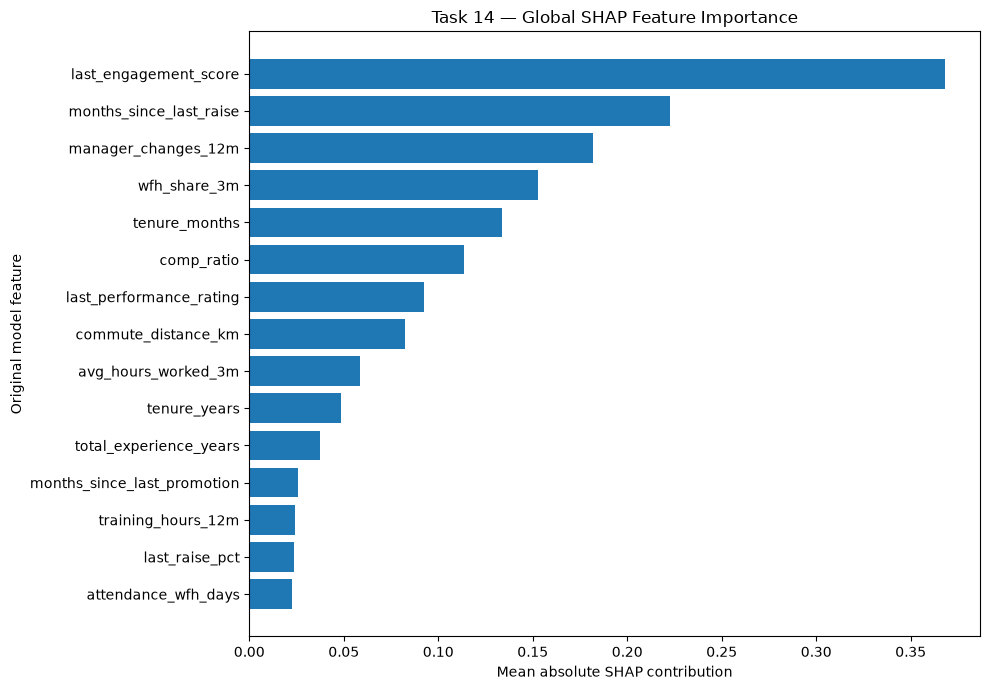

TASK 14 — EVIDENCE EXPORT
.ipynb_checkpoints | 512 bytes
task14_attrition_risk_predictions.csv | 223,283 bytes
task14_employee_shap_reasons.csv | 107,689 bytes
task14_feature_reconstruction_validation.csv | 1,847 bytes
task14_global_shap_importance.csv | 2,167 bytes
task14_methodology_notes.txt | 2,132 bytes
task14_model_feature_order.csv | 1,440 bytes
task14_review_sample_10.csv | 5,341 bytes
task14_risk_band_summary.csv | 295 bytes
task14_shap_summary_bar.png | 126,799 bytes
task14_tenure_fairness_audit.csv | 470 bytes
task14_top_driver_audit.csv | 129,147 bytes

TOTAL EVIDENCE FILES: 12

EVIDENCE FOLDER:
/workspace/reports/task14

TASK 14 EVIDENCE EXPORT COMPLETED


In [206]:
from pathlib import Path
import matplotlib.pyplot as plt

# Create dedicated Task 14 evidence folder
task14_report_dir = ROOT / "reports" / "task14"
task14_report_dir.mkdir(parents=True, exist_ok=True)

# 1. Final official output
risk_output.to_csv(
    task14_report_dir / "task14_attrition_risk_predictions.csv",
    index=False
)

# 2. Top 10 highest-risk employees for human review
review_sample = (
    risk_output
    .sort_values("risk_score_12m", ascending=False)
    .head(10)
    .copy()
)

review_sample.to_csv(
    task14_report_dir / "task14_review_sample_10.csv",
    index=False
)

# 3. Global SHAP importance
global_shap_importance.to_csv(
    task14_report_dir / "task14_global_shap_importance.csv",
    index=False
)

# 4. Three explanations for all employees
employee_reasons.to_csv(
    task14_report_dir / "task14_employee_shap_reasons.csv",
    index=False
)

# 5. Detailed SHAP contributions
top_driver_audit.to_csv(
    task14_report_dir / "task14_top_driver_audit.csv",
    index=False
)

# 6. Original training feature reconstruction validation
feature_reconstruction_validation = pd.concat([
    attendance_validation_v2.assign(dataset="Attendance"),
    payroll_validation_v2.assign(dataset="Payroll")
], ignore_index=True)

feature_reconstruction_validation.to_csv(
    task14_report_dir / "task14_feature_reconstruction_validation.csv",
    index=False
)

# 7. Risk-band summary
risk_band_summary = band_summary.reset_index()

risk_band_summary.to_csv(
    task14_report_dir / "task14_risk_band_summary.csv",
    index=False
)

# 8. Tenure fairness audit
tenure_fairness_summary.to_csv(
    task14_report_dir / "task14_tenure_fairness_audit.csv",
    index=False
)

# 9. Exact model feature order
pd.DataFrame({
    "position": range(1, len(model_feature_order) + 1),
    "feature": model_feature_order
}).to_csv(
    task14_report_dir / "task14_model_feature_order.csv",
    index=False
)

# 10. Global SHAP summary bar chart
plot_data = (
    global_shap_importance
    .head(15)
    .sort_values("mean_absolute_shap")
)

plt.figure(figsize=(10, 7))
plt.barh(
    plot_data["feature"],
    plot_data["mean_absolute_shap"]
)
plt.xlabel("Mean absolute SHAP contribution")
plt.ylabel("Original model feature")
plt.title("Task 14 — Global SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    task14_report_dir / "task14_shap_summary_bar.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close()

# 11. Methodology and limitations documentation
methodology_notes = """
TASK 14 — EXPLAINABLE ATTRITION RISK REPORTS

Observation date: 2026-09-30
Model: attrition-v2
Model type: XGBoost with sigmoid calibration
Employees scored: 430
Model input features: 61

FEATURE RECONSTRUCTION
- 30 missing feature columns were reconstructed.
- 11 attendance features and 14 payroll features were rebuilt
  using the three complete calendar months before the observation month.
- Duplicate employee-month records were averaged before monthly aggregation.
- The reconstruction method was tested against September 2025
  training observations.
- All 25 features matched across 9,650 comparisons.
- Five derived features followed the original Task 2 formulas.
- The original workbook and Task 2 notebook were not modified.

MISSING HISTORY
- 395 employees had three months of prior history.
- 10 employees had two months.
- 8 employees had one month.
- 17 employees had no eligible prior-month history.
- Missing numeric values were handled by the fitted V2 median imputers.
- No manual zero-filling was applied.

RISK BANDS
- High: top 10% of predicted risk scores.
- Medium: next 20%.
- Low: remaining 70%.
- High: 43 employees.
- Medium: 86 employees.
- Low: 301 employees.
- These are relative ranking bands, not validated intervention thresholds.

SHAP EXPLANATIONS
- TreeSHAP explains the underlying XGBoost raw model output.
- Encoded categorical contributions were grouped by original feature.
- Calibration direction was verified against the saved V2 model.
- Three strongest absolute SHAP contributors were recorded per employee.
- SHAP contributions describe model influences, not causal effects.

TENURE FAIRNESS AUDIT
- Descriptive predicted-risk and risk-band representation comparisons.
- Mean predicted risk gap: 7.53 percentage points.
- High-risk representation gap: 12.04 percentage points.
- No observed future attrition outcomes are available for these
  scoring employees; therefore this is not an error-rate fairness test.

HUMAN REVIEW
Predictions are decision-support signals only.
HR must review individual circumstances and must not use scores
as the sole basis for employment decisions.
"""

(task14_report_dir / "task14_methodology_notes.txt").write_text(
    methodology_notes,
    encoding="utf-8"
)

# Verify saved evidence files
print("=" * 70)
print("TASK 14 — EVIDENCE EXPORT")
print("=" * 70)

for file in sorted(task14_report_dir.iterdir()):
    print(f"{file.name} | {file.stat().st_size:,} bytes")

print("\nTOTAL EVIDENCE FILES:",
      len(list(task14_report_dir.iterdir())))

print("\nEVIDENCE FOLDER:")
print(task14_report_dir)

print("\nTASK 14 EVIDENCE EXPORT COMPLETED")